Y  = simulator-generated observed choice (synthetic policy + decision noise); the models are trained on Y.
R* = synthetic decision-policy ground truth (noiseless choice of the same policy). Neither is real controller behaviour.
Self-test passed: the exact filtered ceiling (subset DP) agrees with brute force over all 8! rankings.
QUICK run: seeds 0-2 x 7 worlds; per seed 30 conflicts x 4 contexts = 120 scenarios x 12 simulated controllers = 1440 decisions. Main world W3. max_features = 16.
QUICK mode only checks that the code runs, on development seeds. Do not quote these numbers.

=== 1. DESIGN: the vectors, the seven worlds, the fully crossed matrix ===
Controller-style vector S (simulated tendencies):
  m: preferred separation margin: wanted buffer above the minimum, as a fraction (0.25 = 25% above)
  t: intervention timing: preferred lead time before CPA, seconds (large = acts early)
  r: resolution type: -1 always vertical ... +1 always lateral (heading)
  h: preferred heading-chan

,decision rule,uses style S,uses context C,style intensity reacts to context (iota),controller-specific reaction (rho)
W0: X only,additive,no (average style S-bar),"no (5 NM everywhere, no traffic, no LOA)",no,no
W1: X + S,additive,yes,"no (5 NM everywhere, no traffic, no LOA)",no,no
W2: X + C,additive,no (average style S-bar),yes,no,no
"W3: X + S + C, additive [MAIN]",additive,yes,yes,no,no
W4a: W3 + style intensity reacts to context (iota),additive,yes,yes,yes,no
W4b: W3 + controller-specific reaction (w_rho),additive,yes,yes,no,yes
"W5: X + S + C, non-compensatory (lexicographic)",lexicographic,yes,yes,no,no


Design check: {'cells_per_controller': 4, 'controllers_per_cell': 12, 'conflicts_per_cell': 30, 'max_style_gap_between_cells': 0.0, 'total_decisions': 1440, 'scenarios': 120}


,En-route/low,En-route/high,TMA/low,TMA/high
Controller 0 (conservative),30,30,30,30
Controller 1 (moderate),30,30,30,30
Controller 2 (assertive),30,30,30,30
Controller 3 (conservative),30,30,30,30
Controller 4 (moderate),30,30,30,30
Controller 5 (assertive),30,30,30,30
Controller 6 (conservative),30,30,30,30
Controller 7 (moderate),30,30,30,30
Controller 8 (assertive),30,30,30,30
Controller 9 (conservative),30,30,30,30


Style vectors of the simulated controllers (seed 0; every seed draws new ones):


,ctrl,archetype,m,t,r,h,a,rho
0,0,conservative,0.51,350.97,0.25,8.40,-0.47,0.04
1,1,moderate,0.45,319.67,-0.00,10.64,0.58,-0.65
2,2,assertive,0.05,120.00,-0.48,28.75,0.77,-0.25
3,3,conservative,0.50,336.26,0.57,10.65,-0.72,-0.72
4,4,moderate,0.28,368.69,0.29,18.01,-0.59,0.93
5,5,assertive,0.00,120.00,-0.52,31.26,1.00,0.40
6,6,conservative,0.53,339.87,0.43,13.60,-0.30,0.14
7,7,moderate,0.24,303.89,0.35,18.43,-0.09,-0.89
8,8,assertive,0.00,206.47,-0.04,29.09,0.91,-0.95
9,9,conservative,0.56,462.16,0.81,13.48,-0.19,-0.30


... (38 outputs left out)

[Parallel(n_jobs=-1)]: Done   3 out of   3 | elapsed:    7.6s finished


,M0 recovery %,M1 recovery %,M2 recovery %,M3 recovery %,M3 recovery after filter %
16 conflicts (768 decisions),"84.8 [59.7, 109.8]","86.0 [82.7, 89.3]","79.5 [75.3, 83.8]","71.7 [59.4, 83.9]",81.3
32 conflicts (1536 decisions),"87.1 [66.7, 107.4]","87.3 [82.3, 92.3]","86.0 [82.3, 89.7]","77.7 [70.2, 85.2]",84.5


W5: X + S + C, non-compensatory (lexicographic)


,M0 recovery %,M1 recovery %,M2 recovery %,M3 recovery %,M3 recovery after filter %
16 conflicts (768 decisions),"75.4 [39.5, 111.4]","75.2 [61.3, 89.2]","67.5 [48.6, 86.5]","59.2 [45.8, 72.6]",66.1
32 conflicts (1536 decisions),"84.2 [67.3, 101.1]","82.2 [73.8, 90.5]","75.9 [54.9, 97.0]","68.8 [58.7, 79.0]",75.3


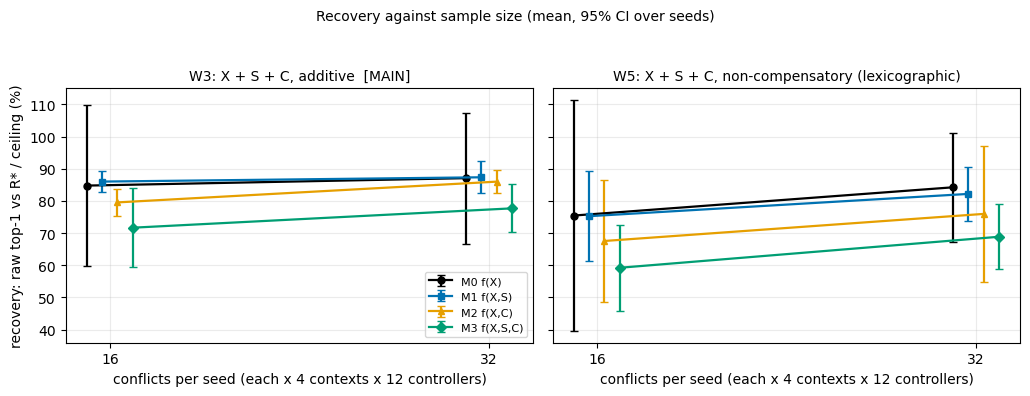

6b. Second learner (gradient-boosted trees) on the same rows and splits as the forest


,random forest: raw top-1 vs R* %,random forest: recovery %,gradient-boosted trees: raw top-1 vs R* %,gradient-boosted trees: recovery %
M0 f(X),41.6,87.4,42.5,89.5
"M1 f(X,S)",60.9,88.9,61.0,89.2
"M2 f(X,C)",51.7,86.3,51.4,85.9
"M3 f(X,S,C)",80.4,80.4,78.1,78.1
"M3id f(X, random 6-dim controller code, C)",79.3,79.3,77.9,77.9


,"C1 contrast M3 - M2, seen controllers, pp","C2 contrast M3 - M3id, new controllers, pp"
random forest,"+28.7 [+9.5, +47.9] (3/3)","+29.9 [+25.9, +33.8] (3/3)"
gradient-boosted trees,"+26.6 [+7.1, +46.2] (3/3)","+23.5 [+5.5, +41.5] (3/3)"



=== 7. PREFERENCE LEVELS and the rule baselines, main world W3 (mean over 3 seeds) ===


,match R* %,P(sim. controller picks it) %
Y simulator-generated observed choice,78.3,69.8
Rule: least deviation among safe candidates (not learned),31.2,31.5
"Rule-pop: the policy with the average style S-bar (not learned, not personalised)",50.7,48.0
"M0 f(X), model alone",41.6,39.6
"M1 f(X,S), model alone",60.9,54.1
"M2 f(X,C), model alone",51.7,47.8
"M3 f(X,S,C), model alone",80.4,68.2
"M3p f(X, S and C shuffled across rows): placebo of M3, model alone",39.3,37.5
"M3pg f(X, S of another controller, C of another scenario): group placebo, model alone",59.9,53.4
"M3id f(X, random 6-dim controller code, C), model alone",79.3,67.8


R* itself matches R* by definition; the simulated controller picks it with probability 78.4%.
Rule-pop knows the policy exactly but treats every controller as the average one (style S-bar). The best any
non-personalised recommender can do is M2's ceiling, which can be higher than Rule-pop.


... (50 outputs left out)

w_rho   (W4b, seen controllers)


gain                              M1 - M0                       M2 - M0  \
param value                                                               
w_rho 0.0    +24.0 [+16.9, +31.0] / +24.4  +11.8 [-26.1, +49.7] / +13.3   
      0.5    +24.5 [+22.7, +26.3] / +25.3  +12.1 [-40.4, +64.6] / +12.6   
      1.0    +24.8 [+21.7, +27.9] / +24.3   +12.2 [-9.0, +33.3] / +12.7   
      2.0    +22.6 [+12.9, +32.3] / +22.6    +9.4 [+2.3, +16.4] / +10.2   
      3.0    +21.0 [+17.9, +24.1] / +21.9    +8.9 [-3.1, +20.8] / +10.1   

gain                              M3 - M0                       M3 - M1  \
param value                                                               
w_rho 0.0    +44.8 [+33.8, +55.9] / +57.6   +20.9 [+2.8, +39.0] / +33.2   
      0.5    +44.1 [+37.5, +50.7] / +57.8  +19.6 [+14.8, +24.5] / +32.4   
      1.0    +43.6 [+41.0, +46.3] / +58.1  +18.8 [+13.0, +24.5] / +33.9   
      2.0    +41.0 [+20.3, +61.7] / +58.8   +18.4 [+7.3, +29.4] / +36.2   
      3.0    +41.1 [+20.8, +61.4] / +59.4   +20.1 [+2.9, +37.3] / +37.5   

gain                              M3 - M2  style dispersion  
param value                                                  
w_rho 0.0     +33.0 [+6.1, +59.9] / +44.3             0.259  
      0.5    +32.0 [-13.9, +77.9] / +45.2             0.259  
      1.0    +31.5 [+12.9, +50.0] / +45.4             0.259  
      2.0     +31.6 [+3.8, +59.4] / +48.5             0.259  
      3.0     +32.3 [+0.1, +64.5] / +49.3             0.259

iota   (W4a, seen controllers)


gain                              M1 - M0                       M2 - M0  \
param value                                                               
iota  0.0    +24.0 [+16.9, +31.0] / +24.4  +11.8 [-26.1, +49.7] / +13.3   
      0.5    +25.2 [+14.6, +35.8] / +24.0   +14.6 [-3.1, +32.2] / +16.0   
      1.0    +23.8 [+13.6, +33.9] / +22.8   +12.6 [+1.2, +24.1] / +15.1   
      1.5     +24.4 [+7.7, +41.2] / +20.6   +14.7 [-9.1, +38.5] / +15.6   
      2.0    +24.2 [+12.7, +35.6] / +20.8  +13.2 [-17.3, +43.6] / +13.7   

gain                              M3 - M0                      M3 - M1  \
param value                                                              
iota  0.0    +44.8 [+33.8, +55.9] / +57.6  +20.9 [+2.8, +39.0] / +33.2   
      0.5    +44.2 [+42.5, +46.0] / +57.9  +19.0 [+6.7, +31.4] / +33.9   
      1.0    +40.5 [+30.8, +50.2] / +55.0  +16.7 [-3.2, +36.6] / +32.2   
      1.5    +38.8 [+35.3, +42.3] / +50.7  +14.4 [+1.1, +27.6] / +30.1   
      2.0    +35.4 [+31.9, +38.9] / +48.2  +11.2 [-3.8, +26.3] / +27.4   

gain                              M3 - M2  style dispersion  
param value                                                  
iota  0.0     +33.0 [+6.1, +59.9] / +44.3             0.258  
      0.5    +29.7 [+13.8, +45.5] / +41.8             0.258  
      1.0    +27.8 [+26.1, +29.6] / +39.9             0.258  
      1.5     +24.1 [-3.3, +51.5] / +35.2             0.258  
      2.0     +22.3 [-4.7, +49.2] / +34.5             0.258

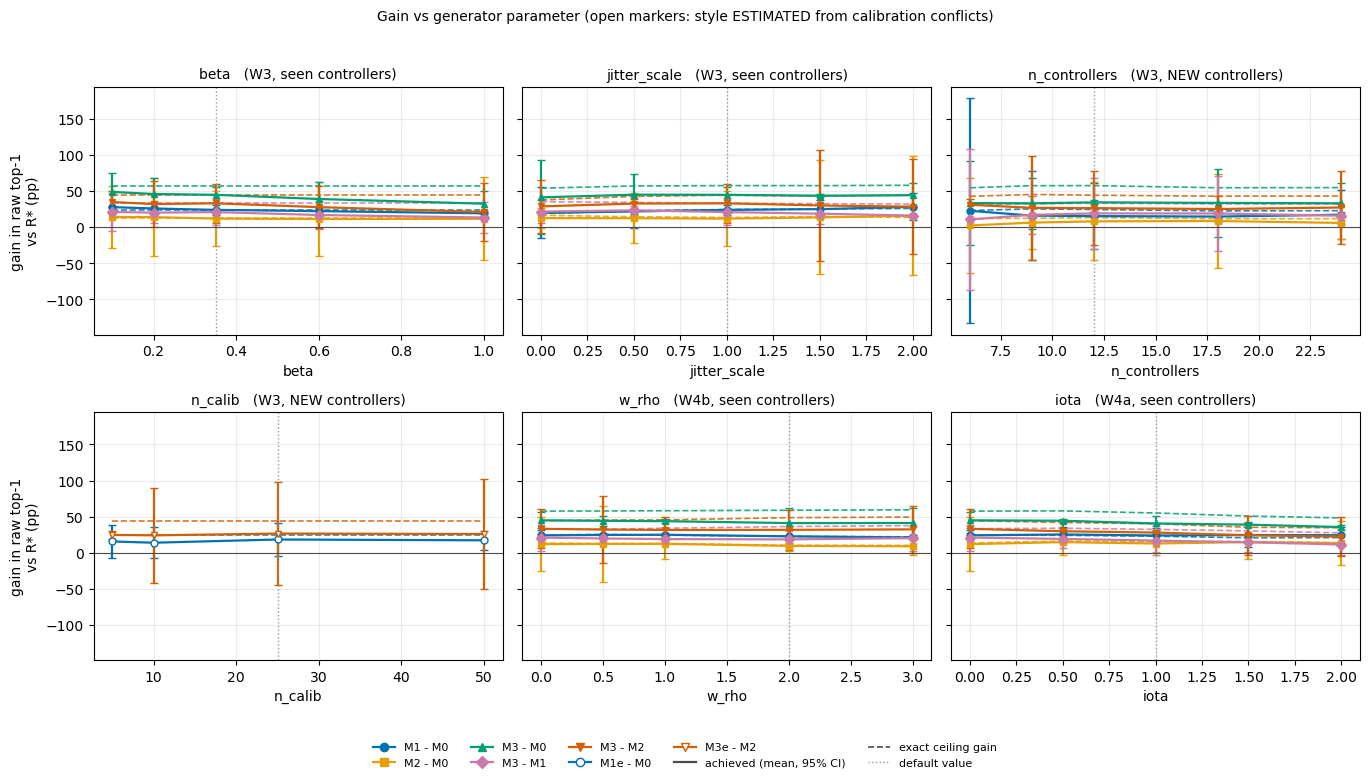


XAI: not part of this prototype. A model-faithful explanation layer, with a fidelity metric, is future work.

Done in 2.3 min.


Exception ignored in: <function ResourceTracker.__del__ at 0x10a359bc0>
Traceback (most recent call last):
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 82, in __del__
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 91, in _stop
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 116, in _stop_locked
ChildProcessError: [Errno 10] No child processes


In [2]:

#   The controllers are SIMULATED decision policies (one style vector each), not measured people.
#   Y  = simulator-generated observed choice: the synthetic policy's pick WITH decision noise. Models learn from Y only.
#   R* = synthetic decision-policy ground truth: the NOISELESS choice of the same policy (exists only in simulation).
#   Neither Y nor R* is the ground truth of real controller behaviour.
#
# STATISTICS (frozen at step 3)
#   Primary metric: raw top-1 vs R*, the share of decisions in which the recommender's own first choice, BEFORE the
#   safety filter, equals R*. Two confirmatory contrasts on the final seeds (one-sided paired t-tests, Holm over both):
#     C1  M3 - M2    seen controllers, folds grouped by conflict: adding the style vector to a context-aware model.
#     C2  M3 - M3id  NEW controllers (stratified random groups), above a minimum effect of 5 pp: on seen controllers a
#                    controller code does as well as the style vector, so the style claim lives on new controllers.
#   All other contrasts are exploratory (one Holm-adjusted family) or descriptive. CIs and p-values measure the
#   MONTE-CARLO error of the simulation, not inference about real controllers.
#
# DESIGN
#   Central ablation: M0 = f(X), M1 = f(X,S), M2 = f(X,C), M3 = f(X,S,C). One learner, same rows, same folds, the same
#   number of features tried per split (max_features). Width-matched placebos M1p, M2p, M3p shuffle S and/or C.
#   Seven worlds label the same scenarios:
#     W0 X | W1 X+S | W2 X+C        controls: the policy ignores S and/or C
#     W3 X+S+C, additive            MAIN world
#     W4a / W4b                     interaction extension (style intensity reacts to context / controller-specific reaction)
#     W5 X+S+C, non-compensatory    lexicographic policy: no criterion can make up for an earlier one
#   HEADLINE: recovery = achieved / analytic ceiling of the same information (raw: best single candidate per group;
#   filtered: best single ranking per group, exact by subset DP). Its sensitivity to sample size and learner is part
#   of the frozen run. Baselines: a least-deviation rule; Rule-pop (the policy itself with the average style S-bar).
#
# MAP   1 config | 2 design | 3 environment and conflict sampling | 4 rules | 5 synthetic policies and worlds
#       6 dataset | 7 models, baselines, splits | 8 safety filter | 9 metrics, ceilings, binding, calibration
#       10 one seed | 11 sweeps, sample-size curve, tuning | 12 statistics and tables | 13 appendix | 14 RUN
# =============================================================================
 
# ---- SETTINGS ---------------------------------------------------------------------------------------------
MODE = "quick"                 # "calibrate" | "tune" | "quick" | "final"  (see HOW TO USE)
N_JOBS = -1                    # parallel processes (-1 = all cores)
RUN_SWEEPS = True              # sweeps are exploratory; False saves about a tenth of the final run
SAVE_CSV = False               # True: write the long result tables to a results/ folder next to the notebook
RUN_APPENDIX = False           # two pictures and a safety-filter before/after example
 
# ---- FROZEN AT STEP 3: the analysis plan. Change nothing here after the freeze. ---------------------------
DEV_SEEDS = list(range(0, 10))        # steps 1-2 and MODE "quick" only: these seeds have been looked at
FINAL_SEEDS = list(range(100, 120))   # steps 4-6: never looked at before the freeze
SWEEP_SEEDS = list(range(200, 205))   # sweeps: never looked at before the freeze
N_CONFLICTS = 100                     # conflicts per seed in the main run (x 4 contexts x 12 controllers)
MAIN_WORLD = "W3"                     # world of the confirmatory tests (additive X + S + C)
PRIMARY = ("match_rstar", " raw")     # raw top-1 vs R*: the model's own first choice, before the safety filter
CONFIRMATORY = [                      # (id, contrast, evaluation, minimum effect in pp): one-sided, Holm over both
    ("C1", "M3 - M2", "cv", 0.0),
    ("C2", "M3 - M3id", "new controllers (random): unseen", 5.0),
]
ALPHA = 0.05                          # family-wise error rate of the two confirmatory tests
SECOND_LEARNER = "hgb"                # gradient-boosted trees (HistGradientBoostingClassifier), hyperparameters in Config
CURVE_SIZES = [50, 100, 200, 400]     # sample-size curve: conflicts per seed (nested subsets), on FINAL_SEEDS
CURVE_WORLDS = ["W3", "W5"]           # worlds of the sample-size curve
SWEEP_PARAMS = ["beta", "jitter_scale", "n_controllers", "n_calib", "w_rho", "iota"]
# Learner hyperparameters live in Config (section 1): n_trees, min_leaf, max_features (fixed with MODE "tune"), hgb_*.
 
# ---- STEP 1 TARGETS: written down BEFORE running MODE "calibrate". Each is (low, high); None = open end. -------
# Model-free quantities only: they describe the generator, so tuning it to meet them cannot favour any model.
TARGETS = {
    # decision noise: Y must follow R* often enough to learn from, not so often that the task is trivial
    "W3: expected Y = R* %": (65, 85),
    "W4a: expected Y = R* %": (65, 85),
    "W4b: expected Y = R* %": (65, 85),
    "W5: expected Y = R* %": (65, 85),
    # room to adapt: the non-adaptive ceiling stays well below 100%, and each axis carries information of its own
    "W3: raw ceiling M0 %": (30, 60),
    "W3: raw ceiling M1 - M0 pp": (10, None),
    "W3: raw ceiling M2 - M0 pp": (5, None),
    "W3: raw ceiling M3 - M1 pp": (10, None),
    "W3: raw ceiling M3 - M2 pp": (10, None),
    "W5: raw ceiling M3 - M2 pp": (10, None),
    # control worlds: information the policy ignores is worth exactly nothing
    "W1: raw ceiling M3 - M1 pp": (0, 0),
    "W2: raw ceiling M3 - M2 pp": (0, 0),
    # rules: separation is already dominant in the policy; the LOA rules change choices where they apply
    "W3: binding R1 %": (None, 1),
    "W3: binding LOA (R2-R4) in TMA %": (5, 30),
    # style: enough variation inside an archetype for the style vector to matter beyond the type label
    "within-type share of style variance (generator): mean of m, t, r, h, a": (0.25, 0.60),
    # interaction: the interaction world has clearly more interaction than the additive one
    "W4b - W3: interaction share of R* pp": (10, None),
}
# -----------------------------------------------------------------------------------------------------------
 
import dataclasses
import itertools
import os
import time
from dataclasses import dataclass, field
 
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from joblib import Parallel, delayed
from scipy import stats
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.metrics import log_loss
from sklearn.model_selection import GroupKFold
 
try:
    from IPython.display import display      # tables in Jupyter / Colab
except ImportError:                          # plain Python: just print
    display = print
 
 
# %% 1. CONFIG - every number of the experiment lives here
# ---- 8 candidate resolutions: heading changes in degrees (+ = right turn), or climb / descend
CANDIDATES = [("H", -30), ("H", -20), ("H", -10), ("H", 10), ("H", 20), ("H", 30), ("V", +1), ("V", -1)]
CAND_NAMES = ["H-30", "H-20", "H-10", "H+10", "H+20", "H+30", "CLIMB", "DESCEND"]
N_CAND = len(CANDIDATES)
IS_LAT = np.array([c[0] == "H" for c in CANDIDATES])
DHDG = np.array([c[1] if c[0] == "H" else 0 for c in CANDIDATES], float)   # signed heading change (deg)
VDIR = np.array([c[1] if c[0] == "V" else 0 for c in CANDIDATES], float)   # +1 climb, -1 descend
BITS = 1 << np.arange(N_CAND)                                              # candidate k <-> bit k
SUBSETS = np.arange(1 << N_CAND)                                           # every set of candidates as a bitmask
JMAX = 48                                                                  # largest number of controllers supported
 
# ---- controller-style vector S = [m, t, r, h, a, rho]  (what a simulated controller TENDS to do)
STYLE_VARS = ["m", "t", "r", "h", "a", "rho"]
STYLE_DOC = {
    "m": "preferred separation margin: wanted buffer above the minimum, as a fraction (0.25 = 25% above)",
    "t": "intervention timing: preferred lead time before CPA, seconds (large = acts early)",
    "r": "resolution type: -1 always vertical ... +1 always lateral (heading)",
    "h": "preferred heading-change magnitude, degrees",
    "a": "altitude preference: -1 prefers descend ... +1 prefers climb",
    "rho": "context reactivity: how the lateral-vs-vertical preference shifts with traffic density "
           "(-1 more vertical in dense traffic ... +1 more lateral); only world W4b uses it",
}
STYLE_BOUNDS = {"m": (0.0, 0.8), "t": (120, 480), "r": (-1, 1), "h": (8, 32), "a": (-1, 1), "rho": (-1, 1)}
# archetypes only GENERATE controllers (centre + jitter) for m, t, r, h, a; rho is drawn on its own.
# The archetype label is used for the archetype hold-out and for reporting; it is never given to a model.
ARCHETYPES = {
    "conservative": dict(m=0.50, t=400, r=+0.5, h=12, a=-0.3),
    "moderate":     dict(m=0.25, t=300, r=0.0, h=20, a=0.0),
    "assertive":    dict(m=0.05, t=200, r=-0.5, h=28, a=+0.4),
}
STYLE_JITTER = dict(m=0.10, t=50, r=0.30, h=3.5, a=0.30)
STYLE_MEAN = {v: float(np.mean([arch[v] for arch in ARCHETYPES.values()])) for v in STYLE_JITTER}
STYLE_MEAN["rho"] = 0.0          # the population-average style S-bar: policies without S, and Rule-pop
 
# ---- context vector C (situation; contains NO controller information)
CONTEXT_DOC = {
    "is_tma": "airspace type: 0 = en-route, 1 = TMA",
    "is_high": "traffic density level: 0 = low, 1 = high",
    "n_nb": "number of surrounding aircraft (realised)",
    "nb_nearest": "distance to the nearest surrounding aircraft (NM)",
    "bnd_dist": "distance to the sector boundary (NM)",
    "bnd_side": "side of the neighbouring sector: -1 left, +1 right",
    "secd_k": "per candidate: min distance to surrounding traffic after the manoeuvre (NM)",
}
 
# ---- worlds: which information the synthetic decision policy is allowed to use, and how it decides
WORLDS = {
    "W0": dict(label="X only", kind="additive", S=False, C=False, iota=False, rho=False),
    "W1": dict(label="X + S", kind="additive", S=True, C=False, iota=False, rho=False),
    "W2": dict(label="X + C", kind="additive", S=False, C=True, iota=False, rho=False),
    "W3": dict(label="X + S + C, additive", kind="additive", S=True, C=True, iota=False, rho=False),
    "W4a": dict(label="W3 + style intensity reacts to context (iota)", kind="additive", S=True, C=True, iota=True, rho=False),
    "W4b": dict(label="W3 + controller-specific reaction (w_rho)", kind="additive", S=True, C=True, iota=False, rho=True),
    "W5": dict(label="X + S + C, non-compensatory (lexicographic)", kind="lexicographic", S=True, C=True, iota=False, rho=False),
}
 
 
@dataclass
class Config:
    seed: int = 0
    # ---- design (fully crossed: every controller x every context cell x every conflict)
    n_controllers: int = 12                                                   # [swept]
    n_conflicts: int = 100            # conflicts per seed; each is replayed in all 4 context cells
    n_calib: int = 25                 # calibration conflicts used to estimate style profiles               [swept]
    calib_pool: int = 50              # calibration conflicts simulated; the first n_calib are used (nested)
    accept_batch: int = 40            # conflicts drawn per batch by the rejection sampler
    airspaces: tuple = ("enroute", "tma")
    densities: tuple = ("low", "high")
    # ---- physics
    dt: float = 5.0                   # s
    response_delay: float = 15.0      # s between instruction and manoeuvre start
    climb_rate: float = 16.7          # ft/s (1000 ft/min)
    vert_step: float = 2000.0         # ft
    v_req: float = 1000.0             # ft vertical minimum
    h_req: dict = field(default_factory=lambda: {"enroute": 5.0, "tma": 3.0})   # NM horizontal minimum
    horizon_extra: float = 180.0      # s simulated after CPA
    slack_step: float = 5.0           # s, grid of instruction delays for the timing slack
    # ---- conflict sampler (identical in every context: X carries no context information)
    t_cpa: tuple = (90.0, 480.0)      # s from decision time to CPA
    d_cpa: tuple = (0.0, 2.4)         # NM predicted miss distance (< both minima: a real conflict)
    speed: tuple = (250.0, 450.0)     # kt
    fl: tuple = (80.0, 200.0)         # flight level of ownship
    dz0: tuple = (-800.0, 800.0)      # ft initial vertical offset (< v_req)
    cross: tuple = (20.0, 170.0)      # deg track crossing angle
    # ---- surrounding traffic (part of the context)
    nb_lambda: dict = field(default_factory=lambda: {"low": 2.0, "high": 12.0})
    nb_radius: float = 40.0           # NM
    nb_dz: float = 2000.0             # ft, uniform +-
    # ---- LOA / operational rules (limited, formalised)
    loa_tma_climb_max_fl: float = 160.0   # R2: in TMA, no climb when ownship is above this FL
    loa_tma_desc_min_fl: float = 100.0    # R2: in TMA, no descent when ownship is below this FL
    loa_boundary_nm: dict = field(default_factory=lambda: {"enroute": 12.0, "tma": 8.0})  # R3: no turn towards boundary if closer
    loa_tma_max_turn: float = 20.0        # R4: in TMA, turns above this need coordination -> not allowed
    # ---- additive policy: U = Safety + geometry + Preference(S) + ContextFit(C) - Deviation
    A_unresolved: float = 6.0
    B_secondary: float = 4.0
    gamma_margin: float = 0.4
    w_m: float = 3.0       # margin shortfall
    w_t: float = 1.0       # timing urgency x decisiveness
    w_r: float = 2.0       # lateral vs vertical
    w_h: float = 1.2       # heading magnitude mismatch
    w_a: float = 0.8       # climb vs descend
    b_type: dict = field(default_factory=lambda: {"enroute": -0.1, "tma": 0.8})   # habit: lateral(+)/vertical(-)
    b_dir: dict = field(default_factory=lambda: {"enroute": 0.0, "tma": 0.5})     # habit: right turns
    kappa_dens: float = 1.2    # high density penalises big lateral manoeuvres
    w_geo: float = 0.05        # geometry tie-breaker (X, every world): all else equal, move vertically AWAY from the intruder
    w_d: float = 0.6           # deviation cost
    dev_vertical: float = 0.4  # normalised deviation of a vertical manoeuvre
    beta: float = 0.35         # decision noise of the additive policies (softmax temperature)        [swept]
    h_req_blind: float = 5.0   # W0, W1: a policy that cannot see the context uses 5 NM everywhere
    iota: float = 1.0          # W4a: style intensity changes with context, the same way for everyone  [swept]
    w_rho: float = 2.0         # W4b: each controller reacts to traffic density in its own direction  [swept]
    jitter_scale: float = 1.0  # multiplies STYLE_JITTER and the spread of rho                         [swept]
    # ---- lexicographic policy (W5)
    lex_type_thr: float = 0.2  # |r| above which the controller's own type beats the sector habit
    lex_dir_thr: float = 0.1   # |a| above which the controller's climb/descend preference is used
    eps_lex: float = 0.25      # decision noise of W5: with this probability another valid candidate, at random
    min_viable: int = 2        # a conflict is accepted if it has >= this many rule-valid candidates in EVERY context
    # ---- learning (frozen at step 3)
    n_trees: int = 100
    min_leaf: int = 2          # minimum samples per leaf of the random forest
    max_features: int = 16     # features tried at each split, the SAME for every model and arm (fixed with MODE "tune")
    hgb_lr: float = 0.1        # second learner: gradient-boosted trees, library defaults except early stopping off
    hgb_iter: int = 200
    hgb_leaves: int = 31
    hgb_min_leaf: int = 20
    n_folds: int = 5
    n_jobs: int = 1            # cores per model (the seeds already run in parallel)
 
 
def h_req_of(cfg, is_tma):
    """Horizontal separation minimum (NM) for an array of is_tma flags."""
    return np.where(np.asarray(is_tma) > 0, cfg.h_req["tma"], cfg.h_req["enroute"])
 
 
# %% 2. DESIGN - controllers (style vectors), contexts, full-factorial matrix
def make_controllers(cfg, rng):
    """Simulated controllers: one style VECTOR S = [m,t,r,h,a,rho] each. Archetypes only seed m..a (centre + jitter);
    rho is drawn on its own stream. jitter_scale scales both spreads. Controllers are drawn one after the other, so the
    first J controllers are the same whatever n_controllers is."""
    names = list(ARCHETYPES)
    rho = np.random.default_rng([cfg.seed, 11]).uniform(-1, 1, cfg.n_controllers) * cfg.jitter_scale
    rows = []
    for j in range(cfg.n_controllers):
        arch = names[j % len(names)]
        s = {k: ARCHETYPES[arch][k] + rng.normal(0, STYLE_JITTER[k] * cfg.jitter_scale) for k in STYLE_JITTER}
        s["rho"] = rho[j]
        for k in STYLE_VARS:
            lo, hi = STYLE_BOUNDS[k]
            s[k] = float(np.clip(s[k], lo, hi))
        rows.append(dict(ctrl=j, archetype=arch, **s))
    return pd.DataFrame(rows)
 
 
def style_dispersion(ctrl, variables=tuple(STYLE_VARS)):
    """Realised spread of the controllers' styles: mean over the given style variables of SD / range of the variable."""
    return float(np.mean([ctrl[v].std(ddof=0) / (STYLE_BOUNDS[v][1] - STYLE_BOUNDS[v][0]) for v in variables]))
 
 
def make_cells(cfg):
    """Context cells = airspace type x traffic density."""
    rows = []
    for z in cfg.airspaces:
        for d in cfg.densities:
            rows.append(dict(cell=len(rows), airspace=z, density=d, is_tma=int(z == "tma"), is_high=int(d == "high"),
                             label=f"{'TMA' if z == 'tma' else 'En-route'}/{d}"))
    return pd.DataFrame(rows)
 
 
def design_matrix(cfg, ctrl, cells):
    """One row = one decision to simulate: (controller, cell, conflict)."""
    idx = pd.MultiIndex.from_product([ctrl.ctrl, cells.cell, range(cfg.n_conflicts)], names=["ctrl", "cell", "conf"])
    return idx.to_frame(index=False)
 
 
def crossing_report(design, ctrl, cells):
    """Rows = controllers, columns = contexts, entries = number of conflicts."""
    tab = design.groupby(["ctrl", "cell"]).size().unstack("cell")
    tab.columns = list(cells.label)
    tab.index = [f"Controller {c} ({a})" for c, a in zip(ctrl.ctrl, ctrl.archetype)]
    return tab
 
 
def check_design(design, ctrl, cells, cfg):
    """Hard checks: raises AssertionError if the design is not balanced / not independent."""
    tab = design.groupby(["ctrl", "cell"]).size().unstack("cell")
    assert tab.shape == (len(ctrl), len(cells)), "some controller x context cell is missing"
    assert (tab.values == cfg.n_conflicts).all(), "unequal number of conflicts per cell"
    paired = design.groupby("conf").size()
    assert (paired == len(ctrl) * len(cells)).all(), "a conflict is not replayed in every controller x context"
    ctx_names = {"is_tma", "is_high", "n_nb", "nb_nearest", "bnd_dist", "bnd_side", "secd_k"}
    assert not (set(STYLE_VARS) & ctx_names), "a variable is in both S and C"
    d = design.merge(ctrl[["ctrl"] + STYLE_VARS], on="ctrl")
    smd = max(abs(d.groupby("cell")[k].mean().max() - d.groupby("cell")[k].mean().min()) / (d[k].std() + 1e-9)
              for k in STYLE_VARS)
    assert smd < 1e-9, f"style differs between context cells (standardised gap {smd:.3g})"
    return {"cells_per_controller": tab.shape[1], "controllers_per_cell": tab.shape[0],
            "conflicts_per_cell": int(tab.values[0, 0]), "max_style_gap_between_cells": float(smd),
            "total_decisions": len(design), "scenarios": cfg.n_conflicts * len(cells)}
 
 
def describe_vectors():
    print("Controller-style vector S (simulated tendencies):")
    for k in STYLE_VARS:
        print(f"  {k}: {STYLE_DOC[k]}")
    print("Context vector C (situation, no controller information):")
    for k, v in CONTEXT_DOC.items():
        print(f"  {k}: {v}")
 
 
# %% 3. ENVIRONMENT - conflicts, surrounding traffic, simulation of the candidates, conflict sampling
KT = 1.0 / 3600.0          # kt -> NM/s
DEV_T = 300.0              # s, fixed time at which lateral deviation is measured
DEV_NORM = 15.0            # NM, lateral displacement that counts as deviation = 1.0
 
 
def _dir(hdg_deg):
    h = np.deg2rad(hdg_deg)
    return np.array([np.sin(h), np.cos(h)])          # (east, north)
 
 
def make_conflicts(cfg, rng):
    """cfg.n_conflicts candidate conflicts: ownship at the origin, intruder placed so CPA happens at t_cpa with miss d_cpa."""
    rows = []
    while len(rows) < cfg.n_conflicts:
        v_o, v_i = rng.uniform(*cfg.speed), rng.uniform(*cfg.speed)
        hdg_o = rng.uniform(0, 360)
        cross = rng.uniform(*cfg.cross) * rng.choice([-1, 1])
        hdg_i = (hdg_o + cross) % 360
        T, d = rng.uniform(*cfg.t_cpa), rng.uniform(*cfg.d_cpa)
        vo, vi = v_o * KT * _dir(hdg_o), v_i * KT * _dir(hdg_i)
        vrel = vi - vo
        if np.linalg.norm(vrel) < 60 * KT:
            continue
        n_hat = np.array([-vrel[1], vrel[0]]) / np.linalg.norm(vrel) * rng.choice([-1, 1])
        p_i0 = vo * T + d * n_hat - vi * T                       # intruder position at t=0
        fl_o, dz0 = rng.uniform(*cfg.fl), rng.uniform(*cfg.dz0)
        bearing = (np.degrees(np.arctan2(p_i0[0], p_i0[1])) - hdg_o + 180) % 360 - 180
        rows.append(dict(conf=len(rows), v_o=v_o, v_i=v_i, hdg_o=hdg_o, hdg_i=hdg_i, fl_o=fl_o, dz0=dz0,
                         t_cpa=T, d_cpa=d, cross=abs(cross), cur_sep=float(np.linalg.norm(p_i0)),
                         intr_bearing=bearing, pxi=p_i0[0], pyi=p_i0[1]))
    return pd.DataFrame(rows)
 
 
def neighbours_for(cfg, c, cell, stream=0):
    """Deterministic surrounding traffic + boundary geometry for (conflict, context cell); stream separates the
    calibration conflicts from the main ones."""
    rng = np.random.default_rng([cfg.seed, 7, int(c["conf"]), int(cell["cell"])] + ([stream] if stream else []))
    lam = cfg.nb_lambda[cell["density"]]
    n = int(np.clip(rng.poisson(lam), 0 if cell["density"] == "low" else 4, 5 if cell["density"] == "low" else 14))
    r = cfg.nb_radius * np.sqrt(rng.uniform(0.02, 1, n))
    ang = rng.uniform(0, 2 * np.pi, n)
    pos = np.stack([r * np.sin(ang), r * np.cos(ang)], 1)
    hdg = rng.uniform(0, 360, n)
    vel = np.stack([rng.uniform(*cfg.speed, n) * KT * np.sin(np.deg2rad(hdg)),
                    rng.uniform(*cfg.speed, n) * KT * np.cos(np.deg2rad(hdg))], 1)
    z = c["fl_o"] * 100 + rng.uniform(-cfg.nb_dz, cfg.nb_dz, n)
    nb = dict(pos=pos, vel=vel, z=z)
    # drop neighbours already in nominal conflict with the ownship (secondary conflicts must come from the manoeuvre)
    keep = np.ones(n, bool)
    if n:
        d_nom, _ = _min_dist(cfg, c, nb, _times(cfg, c), None)
        keep = d_nom >= 1.2 * max(cfg.h_req.values())
    nb = {k: v[keep] for k, v in nb.items()}
    geo = dict(bnd_dist=float(rng.uniform(3, 60)), bnd_side=int(rng.choice([-1, 1])))
    return nb, geo
 
 
def _times(cfg, c):
    """Time grid: from now to CPA + horizon_extra (at least DEV_T so deviation is always measurable)."""
    return np.arange(0, max(c["t_cpa"] + cfg.horizon_extra, DEV_T) + cfg.dt, cfg.dt)
 
 
def _own_path(cfg, c, k, t, extra_delay=0.0):
    """Ownship (xy, z) over time t for candidate k (k=None: no action)."""
    v, d0, tau = c["v_o"] * KT, _dir(c["hdg_o"]), cfg.response_delay + extra_delay
    z0 = c["fl_o"] * 100.0
    if k is None or not IS_LAT[k] and VDIR[k] == 0:
        return v * d0[None, :] * t[:, None], np.full_like(t, z0)
    if IS_LAT[k]:
        d1 = _dir(c["hdg_o"] + DHDG[k])
        xy = v * (d0[None, :] * np.minimum(t, tau)[:, None] + d1[None, :] * np.maximum(t - tau, 0)[:, None])
        return xy, np.full_like(t, z0)
    z = z0 + VDIR[k] * np.minimum(np.maximum(t - tau, 0) * cfg.climb_rate, cfg.vert_step)
    return v * d0[None, :] * t[:, None], z
 
 
def _min_dist(cfg, c, nb, t, k, extra_delay=0.0):
    """Min horizontal distance to each neighbour during times when vertical separation < v_req."""
    own, z_o = _own_path(cfg, c, k, t, extra_delay)
    pos_t = nb["pos"][:, None, :] + nb["vel"][:, None, :] * t[None, :, None]
    dist = np.linalg.norm(own[None] - pos_t, axis=2)
    close = np.abs(z_o[None, :] - nb["z"][:, None]) < cfg.v_req
    return np.where(close, dist, np.inf).min(axis=1), own
 
 
def primary_dmin(cfg, c, k, extra_delay=0.0):
    """Min horizontal distance to the intruder while vertical separation < v_req (NM)."""
    t = _times(cfg, c)
    own, z_o = _own_path(cfg, c, k, t, extra_delay)
    intr = np.array([c["pxi"], c["pyi"]])[None, :] + (c["v_i"] * KT * _dir(c["hdg_i"]))[None, :] * t[:, None]
    dist = np.linalg.norm(own - intr, axis=1)
    z_i = c["fl_o"] * 100.0 + c["dz0"]
    close = np.abs(z_o - z_i) < cfg.v_req
    return float(dist[close].min() if close.any() else dist.min())
 
 
def candidate_outcomes(cfg, c, nb):
    """For one (conflict, context): dmin_k (primary), dev_k (deviation index), secd_k (neighbours), k = 0..7."""
    t = _times(cfg, c)
    nom, _ = _own_path(cfg, c, None, t)
    i_dev = int(DEV_T / cfg.dt)
    dmin, dev, secd = np.zeros(N_CAND), np.zeros(N_CAND), np.full(N_CAND, 99.0)
    for k in range(N_CAND):
        dmin[k] = primary_dmin(cfg, c, k)
        if IS_LAT[k]:
            own, _ = _own_path(cfg, c, k, t)
            dev[k] = np.linalg.norm(own[i_dev] - nom[i_dev]) / DEV_NORM
        else:
            dev[k] = cfg.dev_vertical
        if len(nb["z"]):
            secd[k] = min(99.0, _min_dist(cfg, c, nb, t, k)[0].min())
    return dmin, dev, secd
 
 
def slack_table(cfg, conflicts):
    """Timing slack (s) for every conflict x candidate x minimum (index 0 = en-route 5 NM, 1 = TMA 3 NM): the longest
    delay d such that the candidate resolves for EVERY delay on the grid 0, step, ..., d (0 if it does not resolve even
    without delay). No monotonicity is assumed: the whole grid up to CPA is simulated, and cases where a longer delay
    resolves again after a failure are counted."""
    out, non_monotone = np.zeros((len(conflicts), N_CAND, 2)), 0
    for _, c in conflicts.iterrows():
        delays = np.arange(0.0, c["t_cpa"] + 1e-9, cfg.slack_step)
        for k in range(N_CAND):
            d = np.array([primary_dmin(cfg, c, k, x) for x in delays])
            for i, z in enumerate(("enroute", "tma")):
                ok = d >= cfg.h_req[z]
                n_ok = len(ok) if ok.all() else int(np.argmin(ok))       # length of the run of successes from delay 0
                out[int(c["conf"]), k, i] = delays[n_ok - 1] if n_ok > 0 else 0.0
                non_monotone += int(ok[n_ok:].any())
    return out, 100 * non_monotone / (len(conflicts) * N_CAND * 2)
 
 
def build_scenarios(cfg, conflicts, cells, stream=0):
    """Scenario table = conflict x context cell, with the simulated outcome of every candidate."""
    rows = []
    for _, cell in cells.iterrows():
        for _, c in conflicts.iterrows():
            nb, geo = neighbours_for(cfg, c, cell, stream)
            dmin, dev, secd = candidate_outcomes(cfg, c, nb)
            d_nb = np.linalg.norm(nb["pos"], axis=1) if len(nb["z"]) else np.array([60.0])
            r = dict(conf=int(c["conf"]), cell=int(cell["cell"]), is_tma=int(cell["is_tma"]), is_high=int(cell["is_high"]),
                     n_nb=len(nb["z"]), nb_nearest=float(d_nb.min()), **geo)
            r.update({f"dmin_{k}": dmin[k] for k in range(N_CAND)})
            r.update({f"dev_{k}": dev[k] for k in range(N_CAND)})
            r.update({f"secd_{k}": secd[k] for k in range(N_CAND)})
            rows.append(r)
    scen = pd.DataFrame(rows)
    scen.insert(0, "scen", range(len(scen)))
    return scen.merge(conflicts, on="conf", how="left")
 
 
def sample_conflicts(cfg, rng, cells, n, stream=0):
    """Rejection sampling. Conflicts are drawn in batches and simulated in every context; a conflict is ACCEPTED when it
    has at least min_viable rule-valid candidates in ALL contexts. Then n conflicts are drawn uniformly from the accepted
    pool. Returns (conflicts, scenarios, acceptance statistics)."""
    acc_c, acc_s, drawn = [], [], 0
    solvable = np.zeros(len(cells))
    while sum(len(a) for a in acc_c) < n:
        batch = make_conflicts(dataclasses.replace(cfg, n_conflicts=cfg.accept_batch), rng)
        batch["conf"] = batch["conf"] + drawn
        sc = build_scenarios(cfg, batch, cells, stream)
        ok = sc.assign(ok=valid_mask(cfg, sc).sum(1) >= cfg.min_viable).pivot(index="conf", columns="cell", values="ok")
        solvable += ok.sum(axis=0).values
        good = ok.index[ok.all(axis=1).values]
        acc_c.append(batch[batch.conf.isin(good)])
        acc_s.append(sc[sc.conf.isin(good)])
        drawn += cfg.accept_batch
        if drawn > 100 * n:
            raise RuntimeError("conflict acceptance rate is too low: check the rules or min_viable")
    conflicts, sc = pd.concat(acc_c), pd.concat(acc_s)
    accepted = len(conflicts)
    pick = np.sort(rng.choice(conflicts.conf.values, n, replace=False))          # uniform over the accepted pool
    remap = {c: i for i, c in enumerate(pick)}
    conflicts = conflicts[conflicts.conf.isin(pick)].copy()
    conflicts["conf"] = conflicts.conf.map(remap)
    conflicts = conflicts.sort_values("conf").reset_index(drop=True)
    sc = sc[sc.conf.isin(pick)].copy()
    sc["conf"] = sc.conf.map(remap)
    sc = sc.sort_values(["cell", "conf"]).reset_index(drop=True)
    sc["scen"] = np.arange(len(sc))
    stats_ = dict(drawn=drawn, accepted=accepted, acceptance_rate=accepted / drawn)
    stats_.update({f"solvable in {lab} %": 100 * s / drawn for lab, s in zip(cells.label, solvable)})
    return conflicts, sc, stats_
 
 
# %% 4. RULES - separation minimum and LOA rules (one definition used everywhere; always judged in the REAL context)
RULES = {
    "R1":  "separation minimum: the manoeuvre must resolve the predicted conflict (horizontal minimum by airspace type)",
    "R1b": "no secondary conflict with surrounding traffic",
    "R2":  "LOA level restriction (TMA): no climb above / no descent below the agreed levels",
    "R3":  "LOA transfer condition: no turn towards the sector boundary when closer than the agreed distance",
    "R4":  "LOA coordination (TMA): turns larger than the agreed limit need coordination, so not auto-recommended",
}
 
 
def violations(cfg, sc):
    """dict rule -> bool array (n_rows, 8), True = the candidate VIOLATES the rule."""
    tma = sc.is_tma.values[:, None].astype(bool)
    H = h_req_of(cfg, sc.is_tma.values)[:, None]
    dmin = sc[[f"dmin_{k}" for k in range(N_CAND)]].values
    secd = sc[[f"secd_{k}" for k in range(N_CAND)]].values
    fl = sc.fl_o.values[:, None]
    climb, desc = VDIR[None, :] > 0, VDIR[None, :] < 0
    bnd = np.where(tma, cfg.loa_boundary_nm["tma"], cfg.loa_boundary_nm["enroute"])
    toward = (np.sign(DHDG)[None, :] == sc.bnd_side.values[:, None]) & IS_LAT[None, :]
    return {
        "R1": dmin < H,
        "R1b": secd < H,
        "R2": tma & ((climb & (fl > cfg.loa_tma_climb_max_fl)) | (desc & (fl < cfg.loa_tma_desc_min_fl))),
        "R3": toward & (sc.bnd_dist.values[:, None] < bnd),
        "R4": tma & (np.abs(DHDG)[None, :] > cfg.loa_tma_max_turn),
    }
 
 
def valid_mask(cfg, sc, rules=None):
    """True where a candidate violates NO rule (optionally only the given rules)."""
    v = violations(cfg, sc)
    bad = np.zeros((len(sc), N_CAND), bool)
    for r in (v if rules is None else rules):
        bad |= v[r]
    return ~bad
 
 
# %% 5. SYNTHETIC DECISION POLICIES and the seven worlds
LAT = IS_LAT.astype(float)
MAG = np.abs(DHDG)
DECISIVE = np.where(IS_LAT, MAG / 30.0, 0.8)       # how "decisive" a candidate is (vertical counted as 0.8)
 
 
def _style(ctrl, use_s):
    """(1, J) array per style variable: the controllers' own style, or the population-average style S-bar."""
    J = len(ctrl)
    return ({v: ctrl[v].values[None, :] for v in STYLE_VARS} if use_s
            else {v: np.full((1, J), STYLE_MEAN[v]) for v in STYLE_VARS})
 
 
def policy_utility(cfg, sc, ctrl, world, pop=False):
    """Additive policy. Utility U[scenario, controller, candidate], its named parts, and the margin each controller
    wants (m_eff). Without S every controller has the population-average style (pop=True forces it: Rule-pop); without
    C the policy sees no airspace (5 NM everywhere), no density, no surrounding traffic and no LOA habits. iota: style
    intensity reacts to context (same for everyone). rho: each controller's lateral-vs-vertical preference reacts to
    density in its own direction."""
    W = WORLDS[world]
    n, J = len(sc), len(ctrl)
    dmin = sc[[f"dmin_{k}" for k in range(N_CAND)]].values
    secd = sc[[f"secd_{k}" for k in range(N_CAND)]].values
    dev = sc[[f"dev_{k}" for k in range(N_CAND)]].values
    if W["C"]:
        H = h_req_of(cfg, sc.is_tma.values)[:, None]
        hi, tm = sc.is_high.values[:, None].astype(float), sc.is_tma.values[:, None].astype(float)
    else:
        H = np.full((n, 1), cfg.h_req_blind)
        hi, tm = np.zeros((n, 1)), np.zeros((n, 1))
    mu = (dmin - H) / H                                                     # fractional margin above the minimum
 
    safety = -cfg.A_unresolved * (mu < 0) + cfg.gamma_margin * np.clip(mu, 0, 1)            # (n,K)
    if W["C"]:
        safety = safety - cfg.B_secondary * (secd < H)                      # surrounding traffic belongs to C
    geo = cfg.w_geo * -np.sign(sc.dz0.values)[:, None] * VDIR[None, :]      # (n,K) intruder above -> descend (breaks ties)
 
    st = _style(ctrl, W["S"] and not pop)
    io = cfg.iota if W["iota"] else 0.0
    m = st["m"] * (1 + io * 0.8 * hi)                                      # (n,J) denser traffic -> more margin wanted
    t = st["t"] * (1 + io * 0.5 * hi)                                      # denser traffic -> acts earlier
    h = st["h"] * (1 - io * 0.4 * tm)                                      # TMA -> smaller turns preferred
    r, a = st["r"][:, :, None], st["a"][:, :, None]
    u_time = np.clip((t - sc.t_cpa.values[:, None]) / 300.0, -1, 1)        # >0: the conflict is later than I like
    pref = (-cfg.w_m * np.maximum(0, m[:, :, None] - np.clip(mu, 0, None)[:, None, :])
            + cfg.w_t * u_time[:, :, None] * (DECISIVE[None, None, :] - 0.5)
            + cfg.w_r * r * (LAT[None, None, :] - 0.5)
            - cfg.w_h * ((MAG[None, None, :] - h[:, :, None]) / 10.0) ** 2 * LAT[None, None, :]
            + cfg.w_a * a * VDIR[None, None, :])
    if W["rho"]:   # each controller reacts to dense traffic in its OWN direction: a genuine style x context interaction
        pref = pref + cfg.w_rho * st["rho"][:, :, None] * (hi - 0.5)[:, :, None] * (2 * LAT[None, None, :] - 1)
 
    if W["C"]:
        z = np.where(sc.is_tma.values > 0, "tma", "enroute")
        b_type = np.array([cfg.b_type[v] for v in z])[:, None]
        b_dir = np.array([cfg.b_dir[v] for v in z])[:, None]
        ctx = (b_type * (LAT[None, :] - 0.5) + b_dir * np.sign(DHDG)[None, :]
               - cfg.kappa_dens * hi * (MAG[None, :] / 30.0) * LAT[None, :])                     # (n,K)
    else:
        ctx = np.zeros((n, N_CAND))
    devc = -cfg.w_d * dev                                                                          # (n,K)
    U = safety[:, None, :] + geo[:, None, :] + pref + ctx[:, None, :] + devc[:, None, :]
    return U, dict(safety=safety + geo, pref=pref, ctx=ctx, dev=devc), np.broadcast_to(m, (n, J))
 
 
def style_used(world):
    """Style variables that the world's policy actually uses (the others leave no trace in its choices)."""
    W = WORLDS[world]
    if not W["S"]:
        return []
    used = ["m", "r", "h", "a"] if W["kind"] == "lexicographic" else ["m", "t", "r", "h", "a"]
    return used + (["rho"] if W["rho"] else [])
 
 
def policy_valid(cfg, sc, world):
    """Candidates the policy considers allowed. With C: every rule of section 4.
    Without C the policy cannot know the airspace or the traffic: it only requires 5 NM to the intruder."""
    if WORLDS[world]["C"]:
        return valid_mask(cfg, sc)
    return sc[[f"dmin_{k}" for k in range(N_CAND)]].values >= cfg.h_req_blind
 
 
def lex_choice(cfg, sc, ctrl, pop=False, valid=None):
    """W5: non-compensatory (lexicographic) policy. Each stage keeps only its best candidates and no later stage can
    make up for an earlier one:
      0. rules: candidates that break no rule (real context; `valid` can replace this set);
      1. margin: those that reach the controller's wanted margin m (stage skipped if none does);
      2. type: the controller's own type (lateral if r > +lex_type_thr, vertical if r < -lex_type_thr), otherwise the
         sector habit (lateral in the TMA, vertical en-route), if any candidate of that type is left;
      3. lateral: turn size closest to h; vertical: climb if a > +lex_dir_thr, descend if a < -lex_dir_thr, otherwise
         away from the intruder's level; final tie-break: the larger separation.
    It uses m, r, h, a of the style (not t, not rho). Returns R* (n, J) and the wanted margin m_eff (n, J)."""
    n, J = len(sc), len(ctrl)
    st = _style(ctrl, not pop)
    H = h_req_of(cfg, sc.is_tma.values)[:, None]
    mu = (sc[[f"dmin_{k}" for k in range(N_CAND)]].values - H) / H
    V = valid_mask(cfg, sc) if valid is None else valid
    cand = np.broadcast_to(V[:, None, :], (n, J, N_CAND))
    sat = cand & (mu[:, None, :] >= st["m"][:, :, None])
    cand = np.where(sat.any(2, keepdims=True), sat, cand)
    tma = np.broadcast_to(sc.is_tma.values[:, None].astype(bool), (n, J))
    want_lat = np.where(st["r"] > cfg.lex_type_thr, True, np.where(st["r"] < -cfg.lex_type_thr, False, tma))
    keep = cand & np.where(want_lat[:, :, None], IS_LAT[None, None, :], ~IS_LAT[None, None, :])
    cand = np.where(keep.any(2, keepdims=True), keep, cand)
    want_dir = np.where(st["a"] > cfg.lex_dir_thr, 1.0, np.where(st["a"] < -cfg.lex_dir_thr, -1.0,
                                                                 -np.sign(sc.dz0.values)[:, None]))     # (n, J)
    primary = np.where(IS_LAT[None, None, :], -np.abs(MAG[None, None, :] - st["h"][:, :, None]),
                       (VDIR[None, None, :] == want_dir[:, :, None]).astype(float))
    key = np.where(cand, primary * 1e4 + np.clip(mu, -1, 10)[:, None, :], -np.inf)
    return key.argmax(2), np.broadcast_to(st["m"], (n, J))
 
 
def label_world(base, world):
    """Reference choices of the world's synthetic policy for every decision row:
    Y  (simulator-generated observed choice, with decision noise; the models learn from it),
    R* (synthetic decision-policy ground truth, noiseless), P (exact choice probabilities of the policy),
    m_eff (the margin the simulated controller wants). Every world uses the same noise draws."""
    cfg, sc, ctrl = base["cfg"], base["sc"], base["ctrl"]
    n, J = len(sc), len(ctrl)
    if WORLDS[world]["kind"] == "lexicographic":
        r_star, m_eff = lex_choice(cfg, sc, ctrl)
        V = valid_mask(cfg, sc)
        nv = V.sum(1)
        eps = np.where(nv > 1, cfg.eps_lex, 0.0)          # a single valid candidate leaves nothing to tremble to
        P = np.where(V[:, None, :], (eps / np.maximum(nv - 1, 1))[:, None, None], 0.0) * np.ones((1, J, 1))
        np.put_along_axis(P, r_star[:, :, None], np.broadcast_to((1 - eps)[:, None, None], (n, J, 1)), axis=2)
        other = V[:, None, :] & (np.arange(N_CAND)[None, None, :] != r_star[:, :, None])
        target = np.floor(base["tremble_pick"] * (nv[:, None] - 1)) + 1                 # which of the others
        pick = (np.cumsum(other, axis=2) >= target[:, :, None]).argmax(2)
        y = np.where(base["tremble"] < eps[:, None], pick, r_star)
        U, parts, valid = None, None, V[:, None, :]
    else:
        U3, parts, m_eff = policy_utility(cfg, sc, ctrl, world)
        valid = policy_valid(cfg, sc, world)[:, None, :]
        z = np.where(valid, U3 / cfg.beta, -np.inf)
        z = z - z.max(2, keepdims=True)
        P = np.exp(z)
        P /= P.sum(2, keepdims=True)
        r_star = np.where(valid, U3, -np.inf).argmax(2)
        y = np.where(valid, U3 + cfg.beta * base["gumbel"], -np.inf).argmax(2)
        U = U3.reshape(-1, N_CAND)
    return dict(world=world, U=U, P=P.reshape(-1, N_CAND), y=y.reshape(-1), r_star=r_star.reshape(-1), parts=parts,
                m_eff=np.asarray(m_eff, float).reshape(-1), valid_policy=np.repeat(valid[:, 0, :], J, axis=0))
 
 
def rule_pop(base, world):
    """Rule-pop: the world's own decision rule with the population-average style S-bar, choosing among the candidates
    that break no rule in the real context. Not learned and not personalised: it knows the policy exactly but treats every
    controller as the average one. It is not the best non-personalised ranking (that is M2's ceiling): the choice of the
    average style need not be the most common choice."""
    cfg, sc, ctrl = base["cfg"], base["sc"], base["ctrl"]
    one = ctrl.iloc[:1]
    if WORLDS[world]["kind"] == "lexicographic":
        choice = lex_choice(cfg, sc, one, pop=True)[0][:, 0]
    else:
        U, _, _ = policy_utility(cfg, sc, one, world, pop=True)
        choice = np.where(valid_mask(cfg, sc), U[:, 0, :], -np.inf).argmax(1)
    return np.repeat(choice, len(ctrl))
 
 
# %% 6. DATASET - one row per (scenario, controller); everything that does not depend on the policy
K = range(N_CAND)
X_COLS = (["v_o", "v_i", "fl_o", "hdg_o", "dz0", "t_cpa", "d_cpa", "cross", "cur_sep", "intr_bearing"]
          + [f"dmin_{k}" for k in K] + [f"dev_{k}" for k in K])                 # conflict information (context-free)
S_COLS = list(STYLE_VARS)                                                         # controller-style vector
C_NOSECD = ["is_tma", "is_high", "n_nb", "nb_nearest", "bnd_dist", "bnd_side"]
C_COLS = C_NOSECD + [f"secd_{k}" for k in K]                                      # context vector
EMB_COLS = [f"emb_{i}" for i in range(len(STYLE_VARS))]                           # random controller code, same size as S
MODELS = ("M0", "M1", "M2", "M3")                                                 # the central ablation
FEATURE_SETS = {
    "M0": X_COLS, "M1": X_COLS + S_COLS, "M2": X_COLS + C_COLS, "M3": X_COLS + S_COLS + C_COLS,
    "M1p": X_COLS + [f"{c}~" for c in S_COLS],                                   # width-matched placebo of M1
    "M2p": X_COLS + [f"{c}~" for c in C_COLS],                                   # width-matched placebo of M2
    "M3p": X_COLS + [f"{c}~" for c in S_COLS] + [f"{c}~" for c in C_COLS],      # row-level placebo of M3
    "M3pg": X_COLS + [f"{c}#" for c in S_COLS] + [f"{c}#" for c in C_COLS],     # group-level placebo
    "M3id": X_COLS + EMB_COLS + C_COLS,                                          # controller code instead of S
    "M2ns": X_COLS + C_NOSECD, "M3ns": X_COLS + S_COLS + C_NOSECD,               # without secd_k
}
 
 
def _derangement(m, rng):
    """A permutation of 0..m-1 with no fixed point (nobody keeps their own value)."""
    p = rng.permutation(m)
    while m > 1 and (p == np.arange(m)).any():
        p = rng.permutation(m)
    return p
 
 
def _noise(key, n, J):
    """Decision noise for n scenarios: Gumbel draws (additive worlds) and two uniforms (lexicographic world). Drawn for
    JMAX controllers and cut to J, so the first J controllers get the same noise whatever n_controllers is."""
    assert J <= JMAX, f"n_controllers must be <= {JMAX}"
    rn = np.random.default_rng(key)
    g, t, p = rn.gumbel(size=(n, JMAX, N_CAND)), rn.random((n, JMAX)), rn.random((n, JMAX))
    return g[:, :J], t[:, :J], p[:, :J]
 
 
def _assemble(cfg, ctrl, cells, conflicts, sc, noise, light=False):
    """Decision rows (scenario x controller) and the arrays the experiment needs."""
    n, J = len(sc), len(ctrl)
    i_sc, i_ct = np.repeat(np.arange(n), J), np.tile(np.arange(J), n)
    dec = pd.concat([sc.iloc[i_sc].reset_index(drop=True),
                     ctrl.iloc[i_ct][["ctrl", "archetype"] + S_COLS].reset_index(drop=True)], axis=1)
    b = dict(cfg=cfg, ctrl=ctrl, cells=cells, conflicts=conflicts, sc=sc, dec=dec,
             gumbel=noise[0], tremble=noise[1], tremble_pick=noise[2], valid_real=valid_mask(cfg, dec),
             DMIN=dec[[f"dmin_{k}" for k in K]].values, SECD=dec[[f"secd_{k}" for k in K]].values,
             DEV=dec[[f"dev_{k}" for k in K]].values, H=h_req_of(cfg, dec.is_tma.values),
             conf=dec.conf.values.astype(int), tma=dec.is_tma.values.astype(int), ctrl_id=dec.ctrl.values.astype(int),
             cell_id=dec.cell.values.astype(int), scen_id=dec.scen.values.astype(int))
    b["vbits"] = (b["valid_real"] * BITS[None, :]).sum(1)
    if light:
        return b
    prng = np.random.default_rng([cfg.seed, 31])
    perm_s, perm_c = prng.permutation(len(dec)), prng.permutation(len(dec))
    der_c, der_s = _derangement(J, prng), _derangement(n, prng)
    extra = {f"{c}~": dec[c].values[perm_s] for c in S_COLS}                          # row-level shuffles
    extra.update({f"{c}~": dec[c].values[perm_c] for c in C_COLS})
    extra.update({f"{c}#": ctrl[c].values[der_c][i_ct] for c in S_COLS})             # another controller's S
    extra.update({f"{c}#": sc[c].values[der_s][i_sc] for c in C_COLS})                # another scenario's C
    emb = np.random.default_rng([cfg.seed, 61]).normal(size=(JMAX, len(EMB_COLS)))[:J]
    extra.update({c: emb[i_ct, i] for i, c in enumerate(EMB_COLS)})
    dec = pd.concat([dec, pd.DataFrame(extra)], axis=1)
    b.update(dec=dec, design_check=check_design(design_matrix(cfg, ctrl, cells), ctrl, cells, cfg),
             Xblk=dec[X_COLS].values, Cblk=dec[C_COLS].values, XM={m: dec[cols].values for m, cols in FEATURE_SETS.items()})
    return b
 
 
def _calib(cfg, ctrl, cells, pool):
    """Calibration set: the first n_calib conflicts of the calibration pool. Noise is drawn for the whole pool and then
    cut, so the sets are nested: a larger n_calib only ADDS conflicts (same choices on the ones already there)."""
    cc, csc = pool
    assert cfg.n_calib <= cfg.calib_pool, "n_calib cannot exceed calib_pool"
    noise = _noise([cfg.seed, 22], len(csc), len(ctrl))
    keep = (csc.conf < cfg.n_calib).values
    cc, csc = cc[cc.conf < cfg.n_calib].reset_index(drop=True), csc[keep].reset_index(drop=True)
    csc = csc.assign(scen=np.arange(len(csc)))
    return _assemble(dataclasses.replace(cfg, n_conflicts=cfg.n_calib), ctrl, cells, cc, csc,
                     tuple(a[keep] for a in noise), light=True)
 
 
def build_base(cfg, with_slack=True, with_calibration=True):
    """Controllers, contexts, accepted conflicts and their simulated outcomes, decision noise, timing slack, and a pool of
    calibration conflicts (same controllers) used only to estimate style profiles. Shared by all worlds of a seed.
    Controllers, conflicts and noise come from separate random streams, so changing one leaves the others unchanged."""
    ctrl, cells = make_controllers(cfg, np.random.default_rng([cfg.seed, 1])), make_cells(cfg)
    conflicts, sc, acc = sample_conflicts(cfg, np.random.default_rng([cfg.seed, 2]), cells, cfg.n_conflicts)
    base = _assemble(cfg, ctrl, cells, conflicts, sc, _noise([cfg.seed, 3], len(sc), len(ctrl)))
    base["acceptance"] = acc
    base["slack"] = None
    if with_slack:
        base["slack"], acc["timing slack: non-monotone %"] = slack_table(cfg, conflicts)
    if with_calibration:
        cc, csc, _ = sample_conflicts(dataclasses.replace(cfg, n_conflicts=cfg.calib_pool),
                                      np.random.default_rng([cfg.seed, 21]), cells, cfg.calib_pool, stream=1)
        base["calib_pool"] = (cc, csc)
        base["calib"] = _calib(cfg, ctrl, cells, base["calib_pool"])
    return base
 
 
def rebase(base, cfg):
    """Same conflicts, traffic and noise with new generator parameters (for the sweeps). A change of jitter_scale or
    n_controllers redraws the controllers (same random numbers); a change of n_calib takes another nested subset."""
    old = base["cfg"]
    b = dict(base, cfg=cfg)
    if (cfg.jitter_scale, cfg.n_controllers) != (old.jitter_scale, old.n_controllers):
        ctrl = make_controllers(cfg, np.random.default_rng([cfg.seed, 1]))
        b.update(_assemble(cfg, ctrl, base["cells"], base["conflicts"], base["sc"],
                           _noise([cfg.seed, 3], len(base["sc"]), len(ctrl))))
        if "calib_pool" in base:
            b["calib"] = _calib(cfg, ctrl, base["cells"], base["calib_pool"])
    elif cfg.n_calib != old.n_calib and "calib_pool" in base:
        b["calib"] = _calib(cfg, base["ctrl"], base["cells"], base["calib_pool"])
    return b
 
 
# %% 7. MODELS, BASELINES and EVALUATION SPLITS (one learner for every model; only the inputs differ)
LEARNERS = {"rf": "random forest", "hgb": "gradient-boosted trees"}
 
 
def make_learner(cfg, learner="rf"):
    """The primary learner (random forest) or the second one (gradient-boosted trees). Hyperparameters: Config."""
    if learner == "hgb":
        return HistGradientBoostingClassifier(learning_rate=cfg.hgb_lr, max_iter=cfg.hgb_iter, max_leaf_nodes=cfg.hgb_leaves,
                                              min_samples_leaf=cfg.hgb_min_leaf, early_stopping=False, random_state=cfg.seed)
    return RandomForestClassifier(n_estimators=cfg.n_trees, min_samples_leaf=cfg.min_leaf, max_features=cfg.max_features,
                                  n_jobs=cfg.n_jobs, random_state=cfg.seed)
 
 
def _proba(model, X):
    """Probabilities over all 8 candidates (classes never seen in training get 0)."""
    out = np.zeros((len(X), N_CAND))
    out[:, model.classes_] = model.predict_proba(X)
    return out
 
 
def _fit_predict(cfg, XM, y, tr, te, models, learner="rf"):
    return {m: _proba(make_learner(cfg, learner).fit(XM[m][tr], y[tr]), XM[m][te]) for m in models}
 
 
def cv_by_conflict(base, y, XM, models, learner="rf"):
    """Out-of-fold probabilities: folds grouped by conflict (a conflict is never in training and test)."""
    cfg = base["cfg"]
    out = {m: np.zeros((len(y), N_CAND)) for m in models}
    for tr, te in GroupKFold(n_splits=cfg.n_folds).split(XM["M0"], y, base["conf"]):
        for m, p in _fit_predict(cfg, XM, y, tr, te, models, learner).items():
            out[m][te] = p
    return out
 
 
def rule_choice(base):
    """Non-learned rule baseline (no data, no style, no learning): among the candidates that break no rule in the real
    context, the one with the least deviation; ties go to the larger separation."""
    valid, dev = base["valid_real"], base["DEV"]
    best = np.where(valid, dev, np.inf).min(1, keepdims=True)
    tie = valid & (np.abs(dev - best) < 1e-9)
    return np.where(tie, base["DMIN"], -np.inf).argmax(1)
 
 
def style_profile(cal, lab):
    """Estimated style profile S-hat of every controller, from its choices Y on the calibration conflicts (never used
    for training or testing): what a real system could measure from a controller's history. Same 6 slots as S."""
    dec, ch = cal["dec"], lab["y"]
    rows = np.arange(len(dec))
    lat = IS_LAT[ch]
    hi = dec.is_high.values.astype(bool)
    df = pd.DataFrame(dict(ctrl=dec.ctrl.values,
                           m_hat=np.clip((cal["DMIN"][rows, ch] - cal["H"]) / cal["H"], -1, 2),   # margin achieved
                           t_hat=DECISIVE[ch],                                                    # decisiveness
                           r_hat=lat.astype(float),                                               # lateral share
                           h_hat=np.where(lat, np.abs(DHDG[ch]), np.nan),                         # turn size
                           a_hat=np.where(~lat, (VDIR[ch] > 0).astype(float), np.nan),            # climb share
                           lat_hi=np.where(hi, lat, np.nan), lat_lo=np.where(~hi, lat, np.nan)))
    g = df.groupby("ctrl").mean()
    prof = g[["m_hat", "t_hat", "r_hat", "h_hat", "a_hat"]].assign(rho_hat=g.lat_hi - g.lat_lo)
    return prof.fillna(prof.mean()).fillna(0.0)          # a controller who never turned gets the population value
 
 
def ctrl_groups(base, kind):
    """3 groups of controllers. 'archetype': one whole archetype per group. 'random': stratified, every archetype is
    spread over the groups, so a group is new people of known types."""
    ctrl, k = base["ctrl"], len(ARCHETYPES)
    arch = ctrl.archetype.map({a: i for i, a in enumerate(ARCHETYPES)}).values
    if kind == "archetype":
        return arch
    rng = np.random.default_rng([base["cfg"].seed, 41])
    g, offset = np.empty(len(ctrl), int), int(rng.integers(k))
    for a in range(k):
        ids = rng.permutation(np.where(arch == a)[0])
        g[ids] = (np.arange(len(ids)) + offset + a) % k
    return g
 
 
def cv_new_controllers(base, y, XM, models, kind, conditions=("unseen", "seen, same size"), learner="rf"):
    """New controllers on new conflicts, 3 folds. Fold f tests controller group f on conflict third f (with kind
    'archetype', group f is archetype f, so each fold is one held-out archetype).
    'unseen'         : trained on the other controllers x the other conflicts.
    'seen, same size': trained on ALL controllers x the other conflicts, cut at random to the size of the 'unseen'
                       training set, so the comparison is not confounded by the amount of training data."""
    cfg, k = base["cfg"], len(ARCHETYPES)
    g_ctrl = ctrl_groups(base, kind)[base["ctrl_id"]]
    g_conf = np.random.default_rng([cfg.seed, 42]).permutation(np.arange(cfg.n_conflicts) % k)[base["conf"]]
    rng = np.random.default_rng([cfg.seed, 43])
    out = {c: {m: np.zeros((len(y), N_CAND)) for m in models} for c in conditions}
    tested = np.zeros(len(y), bool)
    for f in range(k):
        te = np.where((g_ctrl == f) & (g_conf == f))[0]
        tr_u = np.where((g_ctrl != f) & (g_conf != f))[0]
        tr_s = rng.choice(np.where(g_conf != f)[0], size=len(tr_u), replace=False)   # drawn always: same stream
        for cond, tr in (("unseen", tr_u), ("seen, same size", tr_s)):
            if cond in conditions:
                for m, p in _fit_predict(cfg, XM, y, tr, te, models, learner).items():
                    out[cond][m][te] = p
        tested[te] = True
    return out, np.where(tested)[0]
 
 
def compositional_split(base, y, XM, models):
    """Secondary experiment. In each context cell, one controller per archetype is removed IN THAT CELL ONLY (a different
    one in every cell): the model has seen them in the other contexts, and the cell with the other controllers, never
    the combination. Trained with the combinations, with them but cut to the same size, and without them."""
    cfg, dec = base["cfg"], base["dec"]
    arch = base["ctrl"].archetype.map({a: i for i, a in enumerate(ARCHETYPES)}).values
    by_arch = [np.where(arch == a)[0] for a in range(len(ARCHETYPES))]
    held = np.zeros(len(dec), bool)
    for c in range(len(base["cells"])):
        ids = [g[c % len(g)] for g in by_arch if len(g)]
        held |= (dec.ctrl.isin(ids) & (dec.cell == c)).values
    rng = np.random.default_rng(cfg.seed + 5)
    in_test = np.isin(base["conf"], rng.choice(cfg.n_conflicts, cfg.n_conflicts // 2, replace=False))
    te = np.where(in_test & held)[0]
    tr_with, tr_without = np.where(~in_test)[0], np.where(~in_test & ~held)[0]
    tr_same = rng.choice(tr_with, size=len(tr_without), replace=False)
    return {"combination in training": _fit_predict(cfg, XM, y, tr_with, te, models),
            "in training, same size": _fit_predict(cfg, XM, y, tr_same, te, models),
            "combination unseen": _fit_predict(cfg, XM, y, tr_without, te, models)}, te
 
 
# %% 8. SAFETY / LOA FILTER - style can change preference, never the rules
def filter_top(base, proba, rows=None):
    """Best-ranked candidate among those that violate no rule in the real context (proba aligned with rows)."""
    valid = base["valid_real"] if rows is None else base["valid_real"][rows]
    return np.where(valid, proba, -1.0).argmax(1)
 
 
def rank_and_filter(cfg, rows, proba):
    """rows: decision rows (scenario columns present); proba: (n, 8). Ranking before / after the filter."""
    valid = valid_mask(cfg, rows)
    order = np.argsort(-proba, axis=1)
    return dict(order=order, valid=valid, top_before=order[:, 0], top_after=np.where(valid, proba, -1.0).argmax(1))
 
 
def demo_text(cfg, rows, proba, i, top_n=4):
    """Before / after ranking for one decision (appendix)."""
    f = rank_and_filter(cfg, rows, proba)
    v = violations(cfg, rows)
    lines = ["Before safety/LOA filtering - model ranks:"]
    for r, k in enumerate(f["order"][i][:top_n], 1):
        bad = [x for x in v if v[x][i, k]]
        lines.append(f"  {r}. {CAND_NAMES[k]:8s} p={proba[i, k]:.2f}" + (f"   INVALID ({', '.join(bad)})" if bad else ""))
    kept = [k for k in f["order"][i] if f["valid"][i, k]][:top_n]
    lines.append("After filtering:")
    for r, k in enumerate(kept, 1):
        lines.append(f"  {r}. {CAND_NAMES[k]:8s} p={proba[i, k]:.2f}")
    return "\n".join(lines)
 
 
# %% 9. METRICS, ANALYTIC CEILINGS and RULE BINDING
METRICS = {   # name: (label, display scale, digits, '+' higher is better / '-' lower is better / '0' no direction)
    "match_rstar": ("match R* %", 100, 1, "+"),
    "accept": ("P(sim. controller picks it) %", 100, 1, "+"),
    "resolved": ("conflict resolved %", 100, 1, "+"),
    "sec_conflict": ("secondary conflict %", 100, 2, "-"),
    "rule_viol": ("rule/LOA violation %", 100, 1, "-"),
    "margin": ("margin above minimum %", 1, 1, "0"),
    "margin_gap": ("|margin - wanted margin|, pp of minimum", 100, 1, "-"),
    "deviation": ("deviation index", 1, 3, "-"),
    "slack_s": ("timing slack (s)", 1, 0, "+"),
    "top1_Y": ("top-1 vs Y %", 100, 1, "+"),
    "top3_Y": ("top-3 vs Y %", 100, 1, "+"),
    "logloss_Y": ("log-loss vs Y", 1, 3, "-"),
    "top1_Rstar": ("top-1 vs R* %", 100, 1, "+"),
    "ceil_top1_Rstar": ("ceiling, top-1 vs R* %", 100, 1, "+"),
    "ceil_top1_Y": ("ceiling, expected top-1 vs Y %", 100, 1, "+"),
    "ceil_match_rstar": ("ceiling, match R* after filter %", 100, 1, "+"),
    "ceil_accept": ("ceiling, P(picks it) after filter %", 100, 1, "+"),
    "filter_intervention": ("filter replaces the model's first choice %", 100, 1, "-"),
    "filter_rescue": ("replacement equals R* %", 100, 1, "+"),
}
PREF_KEYS = ["match_rstar", "accept"]
SAFE_KEYS = ["resolved", "sec_conflict", "rule_viol"]
EFF_KEYS = ["deviation", "margin", "margin_gap", "slack_s"]
ML_KEYS = ["top1_Y", "top3_Y", "logloss_Y", "top1_Rstar"]
 
 
def cdr_metrics(base, lab, ch, rows=None):
    """Apply the chosen resolution in the simulator (ch aligned with rows). Safety is always judged in the REAL context.
    Preference recovery: match with R*, and the probability that the simulated controller would pick it (from P)."""
    rows = np.arange(len(base["dec"])) if rows is None else np.asarray(rows)
    ch = np.asarray(ch)
    H = base["H"][rows]
    dmin, secd, dev = base["DMIN"][rows, ch], base["SECD"][rows, ch], base["DEV"][rows, ch]
    mu = np.clip((dmin - H) / H, -1, 2)
    out = dict(match_rstar=float(np.mean(ch == lab["r_star"][rows])), accept=float(np.mean(lab["P"][rows, ch])),
               resolved=float(np.mean(dmin >= H)), sec_conflict=float(np.mean(secd < H)),
               rule_viol=float(np.mean(~base["valid_real"][rows, ch])), margin=float(np.mean(100 * mu)),
               margin_gap=float(np.mean(np.abs(mu - lab["m_eff"][rows]))), deviation=float(np.mean(dev)))
    if base.get("slack") is not None:
        out["slack_s"] = float(np.mean(base["slack"][base["conf"][rows], ch, base["tma"][rows]]))
    return out
 
 
def filter_effect(lab, raw, filtered, rows=None):
    """How much the safety filter does: share of decisions where it replaces the model's first choice (that choice broke
    a rule), and among those, how often the replacement is R*."""
    rows = np.arange(len(lab["r_star"])) if rows is None else np.asarray(rows)
    changed = np.asarray(raw) != np.asarray(filtered)
    rescue = float(np.mean(np.asarray(filtered)[changed] == lab["r_star"][rows][changed])) if changed.any() else np.nan
    return dict(filter_intervention=float(np.mean(changed)), filter_rescue=rescue)
 
 
def ml_metrics(proba, y, r_star):
    """Classification metrics of predicted probabilities against Y (observed) and R* (noiseless)."""
    top = proba.argmax(1)
    top3 = np.argsort(-proba, axis=1)[:, :3]
    q = np.clip(proba, 1e-6, 1)
    q = q / q.sum(1, keepdims=True)
    return dict(top1_Y=float(np.mean(top == y)), top3_Y=float(np.mean((top3 == y[:, None]).any(1))),
                logloss_Y=float(log_loss(y, q, labels=list(range(N_CAND)))), top1_Rstar=float(np.mean(top == r_star)))
 
 
def filtered_ceiling(gi, vbits, score):
    """Exact best total score of ONE ranking per group after the safety filter (the filter gives each row the
    best-ranked candidate that is valid in that row). Subset DP over the 2^8 sets A of candidates ranked first:
    ranking candidate k next scores every row of the group whose valid set meets A in nothing and contains k."""
    order = np.argsort(gi, kind="stable")
    g_s, vb, sc_ = gi[order], vbits[order], score[order]
    starts = np.flatnonzero(np.r_[True, g_s[1:] != g_s[:-1]])
    free = ((vb[:, None] & SUBSETS[None, :]) == 0).astype(float)            # (rows, 256)
    gains = [np.add.reduceat(free * (((vb >> k) & 1) * sc_[:, k])[:, None], starts, axis=0) for k in range(N_CAND)]
    best = np.full((len(starts), 1 << N_CAND), -np.inf)
    best[:, 0] = 0.0
    for A in range((1 << N_CAND) - 1):
        for k in range(N_CAND):
            if not A >> k & 1:
                B = A | (1 << k)
                best[:, B] = np.maximum(best[:, B], best[:, A] + gains[k][:, A])
    return float(best[:, -1].sum())
 
 
def _selftest_filtered_ceiling(seed=0, groups=3, rows=6):
    """The DP against brute force over all 8! rankings, on random groups and random valid sets."""
    rng = np.random.default_rng(seed)
    gi = np.repeat(np.arange(groups), rows)
    vb = rng.integers(1, 1 << N_CAND, size=len(gi))
    score = rng.random((len(gi), N_CAND))
    perms = np.array(list(itertools.permutations(range(N_CAND))))      # every ranking
    brute = 0.0
    for g in range(groups):
        total = np.zeros(len(perms))
        for i in np.where(gi == g)[0]:
            ok = (vb[i] >> perms) & 1                                   # validity in ranking order
            total += score[i, perms[np.arange(len(perms)), ok.argmax(1)]]  # the filter keeps the first valid one
        brute += total.max()
    assert abs(filtered_ceiling(gi, vb, score) - brute) < 1e-9, "subset DP disagrees with brute force"
 
 
def ceilings(base, lab):
    """Analytic (Bayes) ceilings for each information set, computed from the policy itself over the whole population of
    decisions. Rows that a model cannot tell apart must get the same prediction: M0 sees a conflict (all its rows look
    alike), M1 a conflict x controller, M2 a scenario (conflict x context), M3 every row. Raw: best single candidate per
    group (share of R*; expected share of Y). Filtered: best single RANKING per group after the safety filter (exact,
    subset DP)."""
    J, n = len(base["ctrl"]), len(base["dec"])
    rows = np.arange(n)
    groups = {"M0": base["conf"], "M1": base["conf"] * J + base["ctrl_id"], "M2": base["scen_id"], "M3": rows}
    onehot = np.eye(N_CAND)[lab["r_star"]]
    out = {}
    for m, g in groups.items():
        gi = np.unique(g, return_inverse=True)[1].reshape(-1)
        P_sum = np.zeros((gi.max() + 1, N_CAND))
        np.add.at(P_sum, gi, lab["P"])
        R_cnt = np.zeros((gi.max() + 1, N_CAND))
        np.add.at(R_cnt, (gi, lab["r_star"]), 1)
        d = dict(ceil_top1_Rstar=float(R_cnt.max(1).sum() / n), ceil_top1_Y=float(P_sum.max(1).sum() / n))
        if m == "M3":       # one row per group: rank R* (or the most probable valid candidate) first
            d["ceil_match_rstar"] = float(np.mean(base["valid_real"][rows, lab["r_star"]]))
            d["ceil_accept"] = float(np.mean(np.where(base["valid_real"], lab["P"], -np.inf).max(1)))
        else:
            d["ceil_match_rstar"] = filtered_ceiling(gi, base["vbits"], onehot) / n
            d["ceil_accept"] = filtered_ceiling(gi, base["vbits"], lab["P"]) / n
        out[m] = d
    return out
 
 
CEIL_OF = {"M0": "M0", "M1": "M1", "M2": "M2", "M3": "M3",   # whose ceiling applies (same usable information)
           "M1p": "M0", "M2p": "M0", "M3p": "M0", "M3pg": "M1", "M3id": "M3", "M1e": "M1", "M3e": "M3",
           "M2ns": "M2", "M3ns": "M3", "Rule-pop": "M2"}
BINDING_SETS = {r: [r] for r in RULES}
BINDING_SETS["LOA (R2-R4)"] = ["R2", "R3", "R4"]                # the three LOA rules dropped together
 
 
def binding_rates(base, lab, world):
    """For each rule (and the three LOA rules together): share of decisions whose reference choice R* changes when that
    rule alone is dropped."""
    cfg, sc = base["cfg"], base["sc"]
    n, J = len(sc), len(base["ctrl"])
    rs = lab["r_star"].reshape(n, J)
    cell = sc.cell.values
    out = []
    for r, dropped in BINDING_SETS.items():
        v_wo = valid_mask(cfg, sc, rules=[q for q in RULES if q not in dropped])
        if WORLDS[world]["kind"] == "lexicographic":
            alt = lex_choice(cfg, sc, base["ctrl"], valid=v_wo)[0]
        else:
            alt = np.where(v_wo[:, None, :], lab["U"].reshape(n, J, N_CAND), -np.inf).argmax(2)
        binds = (alt != rs).mean(1)                                        # per scenario
        out += [dict(rule=r, cell=lab_, rate=float(binds[cell == i].mean())) for i, lab_ in enumerate(base["cells"].label)]
        out.append(dict(rule=r, cell="all", rate=float(binds.mean())))
    return out
 
 
def _cube(base, choice):
    """(context cell, conflict, controller) array of candidate indices."""
    return np.asarray(choice).reshape(len(base["cells"]), base["cfg"].n_conflicts, len(base["ctrl"]))
 
 
def variation(base, choice):
    """Share of pairs that get DIFFERENT resolutions: controllers on the same scenario (style) and
    contexts for the same conflict and controller (context)."""
    A = _cube(base, choice)
    J, C = A.shape[2], A.shape[0]
    style = (A[..., :, None] != A[..., None, :]).sum((-1, -2)) / (J * (J - 1))
    B = A.transpose(1, 2, 0)
    ctx = (B[..., :, None] != B[..., None, :]).sum((-1, -2)) / (C * (C - 1))
    return float(style.mean()), float(ctx.mean())
 
 
def interaction_share(base, choice):
    """Two-way decomposition of the share of lateral resolutions (cell x controller, averaged over conflicts):
    controller main effect + context main effect + interaction. Returns the three shares."""
    T = IS_LAT.astype(float)[_cube(base, choice)].mean(1)
    g = T.mean()
    a, b = T.mean(0) - g, T.mean(1) - g
    res = T - g - a[None, :] - b[:, None]
    ss = dict(controller=T.shape[0] * (a ** 2).sum(), context=T.shape[1] * (b ** 2).sum(), interaction=(res ** 2).sum())
    tot = sum(ss.values()) + 1e-12
    return {k: float(v / tot) for k, v in ss.items()}
 
 
def within_type_share_generator(jitter_scale=1.0):
    """Within-type share of style variance as the generator defines it (exact, before clipping): jitter variance over
    jitter variance + variance of the archetype centres. 1 = the archetype says nothing about the variable, 0 = it says
    everything. The style vector can only beat a type label through this share."""
    out = {}
    for v in STYLE_JITTER:
        sw2 = (STYLE_JITTER[v] * jitter_scale) ** 2
        out[v] = sw2 / (sw2 + float(np.var([ARCHETYPES[a][v] for a in ARCHETYPES])))
    return out
 
 
def within_type_share(ctrl):
    """The same share in one seed's drawn controllers (descriptive; with 4 controllers per archetype it runs low)."""
    out = {}
    for v in STYLE_VARS:
        x, g = ctrl[v].values.astype(float), ctrl.archetype.values
        tot = float(np.sum((x - x.mean()) ** 2))
        within = float(sum(np.sum((x[g == a] - x[g == a].mean()) ** 2) for a in np.unique(g)))
        out[v] = within / tot if tot > 0 else np.nan
    return out
 
 
# %% 9b. STEP 1: MODEL-FREE QUANTITIES OF THE GENERATOR (no model is trained; seconds per seed)
def exact_quantities(seed, n_conflicts):
    """Everything step 1 calibrates on, computed from the policies themselves: expected Y = R* agreement, raw and
    filtered ceilings and their gains and synergy, the interaction share of R*, rule binding rates, and the within-type
    share of style variance. One flat dict per seed; TARGETS refers to these names."""
    cfg = Config(seed=seed, n_conflicts=n_conflicts)
    base = build_base(cfg, with_slack=False, with_calibration=False)
    q = {"acceptance %": 100 * base["acceptance"]["acceptance_rate"]}
    for kind, wt in (("generator", within_type_share_generator(cfg.jitter_scale)),
                     ("realised", within_type_share(base["ctrl"]))):
        q.update({f"within-type share of style variance ({kind}): {v}": wt[v] for v in "mtrha"})
        q[f"within-type share of style variance ({kind}): mean of m, t, r, h, a"] = float(np.mean([wt[v] for v in "mtrha"]))
    tma_cells = [lab_ for lab_ in base["cells"].label if lab_.startswith("TMA")]
    for w in WORLDS:
        lab = label_world(base, w)
        q[f"{w}: expected Y = R* %"] = 100 * float(np.mean(lab["P"][np.arange(len(lab["r_star"])), lab["r_star"]]))
        ce = ceilings(base, lab)
        for kind, key in (("raw", "ceil_top1_Rstar"), ("filtered", "ceil_match_rstar")):
            c = {m: 100 * ce[m][key] for m in MODELS}
            q.update({f"{w}: {kind} ceiling {m} %": c[m] for m in MODELS})
            q.update({f"{w}: {kind} ceiling {a} - {b} pp": c[a] - c[b]
                      for a, b in (("M1", "M0"), ("M2", "M0"), ("M3", "M0"), ("M3", "M1"), ("M3", "M2"))})
            q[f"{w}: {kind} ceiling synergy pp"] = c["M3"] - c["M1"] - c["M2"] + c["M0"]
        q[f"{w}: interaction share of R* %"] = 100 * interaction_share(base, lab["r_star"])["interaction"]
        if WORLDS[w]["C"]:
            B = pd.DataFrame(binding_rates(base, lab, w))
            for r in BINDING_SETS:
                q[f"{w}: binding {r} %"] = 100 * float(B[(B.rule == r) & (B.cell == "all")].rate.iloc[0])
                q[f"{w}: binding {r} in TMA %"] = 100 * float(B[(B.rule == r) & B.cell.isin(tma_cells)].rate.mean())
    q["W4b - W3: interaction share of R* pp"] = q["W4b: interaction share of R* %"] - q["W3: interaction share of R* %"]
    return q
 
 
def table_calibration(Q):
    """Step-1 report: every TARGETS quantity over the development seeds (mean, lowest, highest) and whether its mean is
    inside the target; then the rest of the quantities, for information."""
    rows = []
    for name in list(TARGETS) + [c for c in Q.columns if c not in TARGETS and c != "seed"]:
        if name not in Q:
            rows.append({"quantity": name, "target": "?", "mean": np.nan, "lowest": np.nan, "highest": np.nan,
                         "inside target": "unknown quantity"})
            continue
        x = Q[name].astype(float)
        lo, hi = TARGETS.get(name, (None, None))
        ok = ""
        if name in TARGETS:
            m = x.mean()
            ok = "yes" if (lo is None or m >= lo - 1e-9) and (hi is None or m <= hi + 1e-9) else "NO"
        tgt = "" if name not in TARGETS else f"{'' if lo is None else lo} to {'' if hi is None else hi}".strip()
        rows.append({"quantity": name, "target": tgt, "mean": round(x.mean(), 2), "lowest": round(x.min(), 2),
                     "highest": round(x.max(), 2), "inside target": ok})
    return pd.DataFrame(rows).set_index("quantity")
 
 
# %% 10. ONE SEED - all seven worlds on the same scenarios (runs in a parallel worker)
CORE = list(MODELS) + ["M3p"]                                   # learned in every world: the ablation + the placebo
EXTRA = ["M1p", "M2p", "M3pg", "M3id", "M1e", "M3e", "M2ns", "M3ns"]   # main world: placebos, codes, estimated style
GEN_MODELS = ["M0", "M1", "M2", "M3", "M3id", "M3e"]            # models in the new-controller hold-outs
L2_MODELS = ["M0", "M1", "M2", "M3", "M3id"]                    # second learner, folds grouped by conflict
L2_GEN = ["M2", "M3", "M3id"]                                   # second learner, new controllers (random groups)
 
 
def _with_estimated_style(base, lab_cal, XM):
    """Feature matrices of M1e / M3e: S replaced by the style profile estimated from the calibration conflicts."""
    prof = style_profile(base["calib"], lab_cal)
    s_hat = prof.loc[base["ctrl_id"]].values
    XM = dict(XM, M1e=np.hstack([base["Xblk"], s_hat]), M3e=np.hstack([base["Xblk"], s_hat, base["Cblk"]]))
    return XM, prof
 
 
def run_seed(seed, n_conflicts, n_trees, worlds=None, second_learner=True, **overrides):
    """All metrics for one seed. worlds: subset of WORLDS (default all); overrides: Config fields, e.g. w_rho=1.0."""
    cfg = Config(seed=seed, n_conflicts=n_conflicts, n_trees=n_trees, n_jobs=1, **overrides)
    base = build_base(cfg, with_slack=True, with_calibration=True)
    worlds = worlds or list(WORLDS)
    MET, DIST, CHK, PROF, BIND = [], [], [], [], []
    ACC = [dict(seed=seed, **base["acceptance"])]
    arch_of = base["ctrl"].archetype.values[base["ctrl_id"]]          # archetype of every decision row
 
    def add(world, ev, chooser, values):
        MET.extend(dict(seed=seed, world=world, eval=ev, chooser=chooser, metric=k, value=v) for k, v in values.items())
 
    def add_cdr(world, ev, chooser, lab, ch, rows=None):
        met = cdr_metrics(base, lab, ch, rows)
        if chooser.endswith(" filtered") or chooser.startswith("Rule"):      # safe by construction: verified, not tabled
            assert met["rule_viol"] == 0 and met["resolved"] == 1 and met["sec_conflict"] == 0, f"{chooser} is not safe"
        add(world, ev, chooser, met)
 
    def add_dist(world, chooser, ch):
        cells = [("all", np.ones(len(ch), bool))]
        if world == MAIN_WORLD:
            cells += [(lab_, base["cell_id"] == i) for i, lab_ in enumerate(base["cells"].label)]
        for cell, sel in cells:
            shares = np.bincount(np.asarray(ch)[sel], minlength=N_CAND) / sel.sum()
            DIST.extend(dict(seed=seed, world=world, chooser=chooser, cell=cell, candidate=CAND_NAMES[k], share=float(s))
                        for k, s in enumerate(shares))
 
    def add_model(world, ev, m, lab, p, rows=None):
        """A model's raw and filtered choices on the scored rows, its classification metrics and the filter's effect."""
        rows = np.arange(len(lab["y"])) if rows is None else np.asarray(rows)
        raw, filt = p.argmax(1), filter_top(base, p, rows)
        add_cdr(world, ev, f"{m} raw", lab, raw, rows)
        add_cdr(world, ev, f"{m} filtered", lab, filt, rows)
        add(world, ev, m, {**ml_metrics(p, lab["y"][rows], lab["r_star"][rows]), **filter_effect(lab, raw, filt, rows)})
        return raw, filt
 
    # the two free consistency checks: W4a with iota = 0 and W4b with w_rho = 0 are exactly W3
    lab3 = label_world(base, "W3")
    for w, par in (("W4a", "iota"), ("W4b", "w_rho")):
        lz = label_world(dict(base, cfg=dataclasses.replace(cfg, **{par: 0.0})), w)
        assert (lz["y"] == lab3["y"]).all() and (lz["r_star"] == lab3["r_star"]).all(), f"{w} with {par} = 0 is not W3"
 
    rule = rule_choice(base)
    for w in worlds:
        W, main = WORLDS[w], w == MAIN_WORLD
        lab = label_world(base, w)
        y, rs = lab["y"], lab["r_star"]
        assert np.allclose(lab["P"].sum(1), 1) and lab["valid_policy"][np.arange(len(rs)), rs].all(), f"{w}: bad policy"
        sv, cv = variation(base, rs)
        # exact manipulation checks: a policy that ignores S (or C) cannot make R* depend on it
        assert W["S"] or sv == 0.0, f"{w}: R* differs between controllers although the policy ignores S"
        assert W["C"] or cv == 0.0, f"{w}: R* differs between contexts although the policy ignores C"
        XM, models = dict(base["XM"]), list(CORE)
        if main:
            XM, prof = _with_estimated_style(base, label_world(base["calib"], w), XM)
            for j in range(len(base["ctrl"])):
                PROF.append(dict(seed=seed, ctrl=j, archetype=base["ctrl"].archetype[j],
                                 **{v: base["ctrl"][v][j] for v in STYLE_VARS},
                                 **{f"{v}_hat": prof[f"{v}_hat"][j] for v in STYLE_VARS}))
            models += EXTRA
        oof = cv_by_conflict(base, y, XM, models)
        choosers = {"Y": y, "R*": rs, "Rule": rule, "Rule-pop": rule_pop(base, w)}
        for name, ch in choosers.items():
            add_cdr(w, "cv", name, lab, ch)
            add_dist(w, name, ch)
        for m in models:
            add_dist(w, f"{m} filtered", add_model(w, "cv", m, lab, oof[m])[1])
        add(w, "cv", "policy oracle", ml_metrics(lab["P"], y, rs))
        ceil = ceilings(base, lab)
        for m, d in ceil.items():
            add(w, "ceiling", m, d)
        CHK.append(dict(seed=seed, world=w, style_variation=sv, context_variation=cv,
                        interaction_share=interaction_share(base, rs)["interaction"],
                        M3_interaction_share=(interaction_share(base, filter_top(base, oof["M3"]))["interaction"]
                                              if sv + cv > 0 else np.nan),      # undefined when R* never varies (W0)
                        Y_equals_Rstar=float(np.mean(y == rs)),
                        expected_Y_equals_Rstar=float(np.mean(lab["P"][np.arange(len(rs)), rs]))))
        if main or W["kind"] == "lexicographic":
            BIND.extend(dict(seed=seed, world=w, **r) for r in binding_rates(base, lab, w))
        if not main:
            continue
        # new controllers on new conflicts: where the style claim lives (confirmatory contrast C2)
        for kind in ("random", "archetype"):
            res, rows = cv_new_controllers(base, y, XM, GEN_MODELS, kind)
            for cond, preds in res.items():
                for m in GEN_MODELS:
                    raw, filt = add_model(w, f"new controllers ({kind}): {cond}", m, lab, preds[m][rows], rows)
                    if kind == "archetype":                   # each fold holds out one whole archetype
                        for a in ARCHETYPES:
                            sel = arch_of[rows] == a
                            add_cdr(w, f"held-out archetype {a}: {cond}", f"{m} raw", lab, raw[sel], rows[sel])
                            add_cdr(w, f"held-out archetype {a}: {cond}", f"{m} filtered", lab, filt[sel], rows[sel])
        # second learner: the same splits, gradient-boosted trees instead of the forest
        if second_learner:
            L = SECOND_LEARNER
            oof2 = cv_by_conflict(base, y, XM, L2_MODELS, learner=L)
            for m in L2_MODELS:
                add_model(w, f"cv [{L}]", m, lab, oof2[m])
            res2, rows2 = cv_new_controllers(base, y, XM, L2_GEN, "random", conditions=("unseen",), learner=L)
            for m in L2_GEN:
                add_model(w, f"new controllers (random) [{L}]: unseen", m, lab, res2["unseen"][m][rows2], rows2)
        # unseen controller x context combinations (secondary)
        res, te = compositional_split(base, y, XM, list(MODELS))
        for ev, preds in res.items():
            for m in MODELS:
                add_model(w, ev, m, lab, preds[m], te)
    return MET, DIST, CHK, ACC, PROF, BIND
 
 
# %% 11. PARAMETER SWEEPS - gains and their ceiling gains as curves over the generator parameters
SWEEP_SPECS = {   # parameter: (world, values, evaluation); the other parameters stay at their defaults
    # evaluation 'seen': folds grouped by conflict, as in the main results. 'new': new controllers on new conflicts
    # (stratified random groups). For seen controllers any consistent code is enough to personalise (M3id, M3pg), so
    # the number of controllers and the calibration size matter mainly for NEW controllers.
    "beta": (MAIN_WORLD, [0.1, 0.2, 0.35, 0.6, 1.0], "seen"),
    "jitter_scale": (MAIN_WORLD, [0.0, 0.5, 1.0, 1.5, 2.0], "seen"),
    "n_controllers": (MAIN_WORLD, [6, 9, 12, 18, 24], "new"),
    "n_calib": (MAIN_WORLD, [5, 10, 25, 50], "new"),
    "w_rho": ("W4b", [0.0, 0.5, 1.0, 2.0, 3.0], "seen"),
    "iota": ("W4a", [0.0, 0.5, 1.0, 1.5, 2.0], "seen"),
}
SWEEP_CONTRASTS = {   # contrasts drawn per panel; the n_calib panel follows the models with ESTIMATED style
    "core": {"M1 - M0": {"M1": 1, "M0": -1}, "M2 - M0": {"M2": 1, "M0": -1}, "M3 - M0": {"M3": 1, "M0": -1},
             "M3 - M1": {"M3": 1, "M1": -1}, "M3 - M2": {"M3": 1, "M2": -1}},
    "n_calib": {"M1e - M0": {"M1e": 1, "M0": -1}, "M3e - M2": {"M3e": 1, "M2": -1}},
}
 
 
def _sweep_predict(b, lab, XM, models, how):
    """Out-of-sample probabilities and the rows they are scored on: every row (folds grouped by conflict) or the test
    rows of the new-controller split (stratified random groups, 'unseen' condition)."""
    if how == "seen":
        return cv_by_conflict(b, lab["y"], XM, models), np.arange(len(lab["y"]))
    res, rows = cv_new_controllers(b, lab["y"], XM, models, "random", conditions=("unseen",))
    return {m: p[rows] for m, p in res["unseen"].items()}, rows
 
 
def run_sweep_seed(seed, n_conflicts, n_trees, params):
    """One seed of every sweep. All points share the seed's conflicts, traffic and decision noise. The ceilings are
    always those of the whole population: for new controllers, a ceiling computed on the few test controllers would let
    M0 and M2 'know' who they are."""
    cfg = Config(seed=seed, n_conflicts=n_conflicts, n_trees=n_trees, n_jobs=1)
    base = build_base(cfg, with_slack=False, with_calibration="n_calib" in params)
    rec = []
 
    def record(param, v, b, world, how, lab, preds, rows, ceil):
        for m, p in preds.items():
            rec.append(dict(seed=seed, param=param, value=v, world=world, evaluation=how, model=m,
                            raw=float(np.mean(p.argmax(1) == lab["r_star"][rows])),
                            filtered=float(np.mean(filter_top(b, p, rows) == lab["r_star"][rows])),
                            ceil_raw=ceil[CEIL_OF[m]]["ceil_top1_Rstar"],
                            ceil_filtered=ceil[CEIL_OF[m]]["ceil_match_rstar"],
                            dispersion=style_dispersion(b["ctrl"], style_used(world) or STYLE_VARS)))
 
    for param in params:
        world, values, how = SWEEP_SPECS[param]
        if param == "n_calib":                       # M0 and M2 do not depend on n_calib: fitted once
            lab = label_world(base, world)
            fixed, rows = _sweep_predict(base, lab, base["XM"], ["M0", "M2"], how)
            ceil = ceilings(base, lab)
        for v in values:
            b = rebase(base, dataclasses.replace(cfg, **{param: v}))
            if param == "n_calib":
                XM, _ = _with_estimated_style(b, label_world(b["calib"], world), b["XM"])
                preds = dict(fixed, **_sweep_predict(b, lab, XM, ["M1e", "M3e"], how)[0])
            else:
                lab = label_world(b, world)
                preds, rows = _sweep_predict(b, lab, b["XM"], list(MODELS), how)
                ceil = ceilings(b, lab)
            record(param, v, b, world, how, lab, preds, rows, ceil)
    return rec
 
 
# %% 11b. SAMPLE-SIZE CURVE - recovery as the number of conflicts per seed grows (nested subsets of one draw)
def subset_conflicts(base, n):
    """The first n conflicts of a base: same controllers, and the same traffic and decision noise on those conflicts."""
    keep = (base["sc"].conf < n).values
    sc = base["sc"][keep].reset_index(drop=True)
    sc["scen"] = np.arange(len(sc))
    conflicts = base["conflicts"][base["conflicts"].conf < n].reset_index(drop=True)
    noise = (base["gumbel"][keep], base["tremble"][keep], base["tremble_pick"][keep])
    b = _assemble(dataclasses.replace(base["cfg"], n_conflicts=n), base["ctrl"], base["cells"], conflicts, sc, noise)
    b.update(acceptance=base["acceptance"], slack=None)
    return b
 
 
def run_curve_seed(seed, sizes, n_trees, worlds):
    """Raw and filtered recovery of M0-M3 at each sample size (conflicts per seed) in each world, for one seed."""
    cfg = Config(seed=seed, n_conflicts=max(sizes), n_trees=n_trees, n_jobs=1)
    full = build_base(cfg, with_slack=False, with_calibration=False)
    rec = []
    for n in sorted(sizes):
        b = full if n == max(sizes) else subset_conflicts(full, n)
        for w in worlds:
            lab = label_world(b, w)
            oof = cv_by_conflict(b, lab["y"], b["XM"], list(MODELS))
            ce = ceilings(b, lab)
            for m in MODELS:
                rec.append(dict(seed=seed, world=w, n_conflicts=n, model=m,
                                raw=float(np.mean(oof[m].argmax(1) == lab["r_star"])), ceil_raw=ce[m]["ceil_top1_Rstar"],
                                filtered=float(np.mean(filter_top(b, oof[m]) == lab["r_star"])),
                                ceil_filtered=ce[m]["ceil_match_rstar"]))
    return rec
 
 
# %% 11c. STEP 2: max_features ON THE DEVELOPMENT SEEDS (the only learner hyperparameter tuned)
TUNE_GRID = [4, 6, 8, 12, 16, 24]
TUNE_TOL_PP = 0.5            # a value is on a model's plateau when its mean is within this of the model's best
 
 
def run_tune_seed(seed, n_conflicts, n_trees, grid):
    """Raw top-1 vs R* of M0-M3 in the main world for every max_features value of the grid, for one seed."""
    cfg = Config(seed=seed, n_conflicts=n_conflicts, n_trees=n_trees, n_jobs=1)
    base = build_base(cfg, with_slack=False, with_calibration=False)
    lab = label_world(base, MAIN_WORLD)
    rec = []
    for mf in grid:
        b = dict(base, cfg=dataclasses.replace(cfg, max_features=mf))
        oof = cv_by_conflict(b, lab["y"], b["XM"], list(MODELS))
        rec += [dict(seed=seed, max_features=mf, model=m, raw=float(np.mean(oof[m].argmax(1) == lab["r_star"])))
                for m in MODELS]
    return rec
 
 
def tune_report(T):
    """Mean raw top-1 vs R* (%) per max_features and model; each model's plateau start; the value to freeze (the
    largest plateau start, so that every model is on its plateau)."""
    t = (100 * T.groupby(["max_features", "model"]).raw.mean().unstack("model")).round(2)
    best = t.max(axis=0)
    plateau = {m: int(min(v for v in t.index if t.loc[v, m] >= best[m] - TUNE_TOL_PP)) for m in t.columns}
    return t, plateau, max(plateau.values())
 
 
# %% 12. STATISTICS AND TABLES - means over seeds; gains are paired differences across seeds, mean [95% CI]
CONTRASTS = {
    "M1 - M0": {"M1": 1, "M0": -1},
    "M2 - M0": {"M2": 1, "M0": -1},
    "M3 - M0": {"M3": 1, "M0": -1},
    "M3 - M1": {"M3": 1, "M1": -1},
    "M3 - M2": {"M3": 1, "M2": -1},
    "synergy (M3-M1-M2+M0)": {"M3": 1, "M1": -1, "M2": -1, "M0": 1},
    "M3 - M3p (information, equal width)": {"M3": 1, "M3p": -1},
    "M3p - M0 (input width alone)": {"M3p": 1, "M0": -1},
}
_ADD = ["+", "+", "+", "+", "+", "not fixed by design", "+", "0 or below"]
EXPECTED = {   # gains implied by the construction of each world ('0' = there is no information to gain)
    "W0": ["0", "0", "0", "0", "0", "0", "0", "0 or below"],
    "W1": ["+", "0", "+", "0", "+", "0", "+", "0 or below"],
    "W2": ["0", "+", "+", "+", "0", "0", "+", "0 or below"],
    "W3": _ADD, "W4a": _ADD, "W4b": _ADD, "W5": _ADD,
}
ROBUST = {
    "M1 - M1p: information in S at equal width (placebo of M1)": {"M1": 1, "M1p": -1},
    "M2 - M2p: information in C at equal width (placebo of M2)": {"M2": 1, "M2p": -1},
    "M3 - M3p: information in S and C at equal width (placebo of M3)": {"M3": 1, "M3p": -1},
    "M3 - M3pg: information in S and C beyond group codes (group placebo)": {"M3": 1, "M3pg": -1},
    "M3pg - M0: a controller code alone (group placebo)": {"M3pg": 1, "M0": -1},
    "M3 - M3id: style vector vs a random 6-dim controller code": {"M3": 1, "M3id": -1},
    "M1e - M0: personalisation with ESTIMATED style": {"M1e": 1, "M0": -1},
    "M3e - M2: estimated style added to context": {"M3e": 1, "M2": -1},
    "M3 - M3e: cost of having to estimate the style": {"M3": 1, "M3e": -1},
    "M2ns - M0: context without secd_k": {"M2ns": 1, "M0": -1},
    "M3 - M3ns: what secd_k adds": {"M3": 1, "M3ns": -1},
}
GEN_CONTRASTS = {
    "M1 - M0": {"M1": 1, "M0": -1},
    "M3 - M2": {"M3": 1, "M2": -1},
    "M3 - M3id (style vector vs code)": {"M3": 1, "M3id": -1},
    "M3e - M2 (estimated style)": {"M3e": 1, "M2": -1},
    "M3id - M2 (controller code)": {"M3id": 1, "M2": -1},
}
ALL_CONTRASTS = {**CONTRASTS, **GEN_CONTRASTS, "M3 - M3id": {"M3": 1, "M3id": -1}}
KINDS = {"raw": ("match_rstar", " raw"), "filtered": ("match_rstar", " filtered")}   # primary, secondary
NEW_RANDOM = "new controllers (random): unseen"
NICE = {"Y": "Y  simulator-generated observed choice", "R*": "R* synthetic decision-policy ground truth",
        "Rule": "Rule: least deviation among safe candidates (not learned)",
        "Rule-pop": "Rule-pop: the policy with the average style S-bar (not learned, not personalised)",
        "policy oracle": "policy oracle (exact choice probabilities = ceiling)",
        "M0": "M0 f(X)", "M1": "M1 f(X,S)", "M2": "M2 f(X,C)", "M3": "M3 f(X,S,C)",
        "M1p": "M1p f(X, S shuffled across rows): placebo of M1",
        "M2p": "M2p f(X, C shuffled across rows): placebo of M2",
        "M3p": "M3p f(X, S and C shuffled across rows): placebo of M3",
        "M3pg": "M3pg f(X, S of another controller, C of another scenario): group placebo",
        "M3id": "M3id f(X, random 6-dim controller code, C)",
        "M1e": "M1e f(X, estimated S)", "M3e": "M3e f(X, estimated S, C)",
        "M2ns": "M2ns f(X, C without secd_k)", "M3ns": "M3ns f(X, S, C without secd_k)"}
for _m in CORE + EXTRA:
    NICE[f"{_m} raw"] = f"{NICE[_m]}, model alone"
    NICE[f"{_m} filtered"] = f"{NICE[_m]} + safety filter"
SWEEP_COLORS = {"M1 - M0": ("#0072B2", "o", True), "M2 - M0": ("#E69F00", "s", True), "M3 - M0": ("#009E73", "^", True),
                "M3 - M1": ("#CC79A7", "D", True), "M3 - M2": ("#D55E00", "v", True),   # Okabe-Ito colours, fixed order
                "M1e - M0": ("#0072B2", "o", False), "M3e - M2": ("#D55E00", "v", False)}   # open marker = estimated S
MODEL_COLORS = {"M0": ("#000000", "o"), "M1": ("#0072B2", "s"), "M2": ("#E69F00", "^"), "M3": ("#009E73", "D")}
REFERENCES = ("Y", "R*", "Rule", "Rule-pop", "policy oracle")      # choosers that are not models (no raw/filtered)
ARM_ORDER = list(MODELS) + ["M1p", "M2p", "M3p", "M3pg", "M3id", "M1e", "M3e", "M2ns", "M3ns"]   # display order
 
 
def wl(w):
    return f"{w}: {WORLDS[w]['label']}" + ("  [MAIN]" if w == MAIN_WORLD else "")
 
 
def ci95(x):
    """Mean and 95% t-interval across seeds (Monte-Carlo error of the simulation)."""
    x = np.asarray(x, float)
    m = float(x.mean())
    if len(x) < 2:
        return m, np.nan, np.nan
    h = float(stats.t.ppf(0.975, len(x) - 1) * x.std(ddof=1) / np.sqrt(len(x)))
    return m, m - h, m + h
 
 
def p_value(x, alternative="two-sided"):
    """Paired t-test across seeds of a per-seed contrast (Monte-Carlo error, not population inference)."""
    x = np.asarray(x, float)
    n, m = len(x), float(np.mean(x))
    if n < 2:
        return np.nan
    s = float(x.std(ddof=1))
    if s == 0:
        return 0.0 if (m > 0 or (alternative == "two-sided" and m != 0)) else 1.0
    t = m / (s / np.sqrt(n))
    return float(2 * stats.t.sf(abs(t), n - 1) if alternative == "two-sided" else stats.t.sf(t, n - 1))
 
 
def holm(p):
    """Holm step-down adjustment of a family of p-values."""
    p = np.asarray(p, float)
    order, adj, running = np.argsort(p), np.empty(len(p)), 0.0
    for rank, i in enumerate(order):
        running = max(running, (len(p) - rank) * p[i])
        adj[i] = min(1.0, running)
    return adj
 
 
def fmt_gain(x, metric):
    """'mean [low, high] (k/n)' in display units (pp for rates); k = seeds in which the gain goes the good way."""
    _, scale, digits, better = METRICS[metric]
    x = np.asarray(x, float)
    m, lo, hi = ci95(x * scale)
    out = f"{m:+.{digits}f} [{lo:+.{digits}f}, {hi:+.{digits}f}]"
    if better == "0":                     # no better direction: no count of seeds 'in favour'
        return out
    return f"{out} ({int(((x > 0) if better == '+' else (x < 0)).sum())}/{len(x)})"
 
 
def series(MET, world, ev, chooser, metric):
    """One value per seed."""
    s = MET[(MET.world == world) & (MET["eval"] == ev) & (MET.chooser == chooser) & (MET.metric == metric)]
    return s.set_index("seed").value.sort_index()
 
 
def contrast(MET, world, ev, metric, suffix, coefs):
    """Per-seed linear combination of choosers (suffix ' raw' / ' filtered' applies to models, not to references)."""
    return sum(c * series(MET, world, ev, m if m in REFERENCES else f"{m}{suffix}", metric) for m, c in coefs.items())
 
 
def _col(metric, suffix):
    lab, _, _, better = METRICS[metric]
    where = {" raw": ", model alone", " filtered": ", after filter", "": ""}[suffix]
    if (metric, suffix) == PRIMARY:
        lab, where = "PRIMARY: raw top-1 vs R* %", ""
    return f"{lab}{where} ({ {'+': 'higher is better', '-': 'lower is better', '0': 'no better direction'}[better] })"
 
 
def _level(MET, world, ev, chooser, metric):
    _, scale, digits, _ = METRICS[metric]
    s = series(MET, world, ev, chooser, metric)
    return round(s.mean() * scale, digits) if len(s) else np.nan
 
 
def recovery(MET, world, model, ev="cv", kind="raw"):
    """Per-seed recovery = achieved / exact ceiling of the same information. 'raw' (primary): top-1 vs R* of the model
    alone over the best single candidate per group. 'filtered': match R* after the filter over the best ranking."""
    metric, suffix = KINDS[kind]
    a = series(MET, world, ev, model if model in REFERENCES else f"{model}{suffix}", metric)
    c = series(MET, world, "ceiling", CEIL_OF[model], "ceil_top1_Rstar" if kind == "raw" else "ceil_match_rstar")
    return a / c
 
 
def table_worlds():
    rows = {}
    for w, d in WORLDS.items():
        rows[wl(w)] = {"decision rule": d["kind"],
                       "uses style S": "yes" if d["S"] else "no (average style S-bar)",
                       "uses context C": "yes" if d["C"] else "no (5 NM everywhere, no traffic, no LOA)",
                       "style intensity reacts to context (iota)": "yes" if d["iota"] else "no",
                       "controller-specific reaction (rho)": "yes" if d["rho"] else "no"}
    return pd.DataFrame(rows).T
 
 
def table_acceptance(ACC):
    m = ACC.drop(columns="seed").mean()
    out = pd.DataFrame({"mean over seeds": m}).T
    out["acceptance_rate"] = 100 * out["acceptance_rate"]
    return out.rename(columns={"acceptance_rate": "accepted %"}).round(1)
 
 
def table_checks(CHK):
    g = CHK.groupby("world")[["style_variation", "context_variation", "interaction_share", "M3_interaction_share",
                              "expected_Y_equals_Rstar", "Y_equals_Rstar"]].mean().reindex(list(WORLDS))
    out = pd.DataFrame({"R* differs between controllers %": 100 * g.style_variation,
                        "R* differs between contexts %": 100 * g.context_variation,
                        "interaction share of R* %": 100 * g.interaction_share,
                        "interaction share of M3 recommendations %": 100 * g.M3_interaction_share,
                        "expected Y = R* % (exact)": 100 * g.expected_Y_equals_Rstar,
                        "Y = R* % (realised)": 100 * g.Y_equals_Rstar}).round(1)
    out.index = [wl(w) for w in out.index]
    return out
 
 
def table_binding(BIND, world):
    t = BIND[BIND.world == world].groupby(["rule", "cell"]).rate.mean().unstack("cell")
    t = (100 * t).reindex(index=list(BINDING_SETS), columns=list(make_cells(Config()).label) + ["all"]).round(2)
    t.index = [f"{r}: {RULES[r].split(':')[0]}" if r in RULES else f"{r}: all three LOA rules dropped together"
               for r in t.index]
    return t
 
 
def table_headline(MET, world=MAIN_WORLD):
    """PRIMARY. Raw top-1 vs R* (the model's own first choice, before the filter): achieved, the exact ceiling of the
    same information (best single candidate per group), and recovery = achieved / ceiling per seed, mean [95% CI].
    Rule-pop is measured against M2's ceiling (it has M2's information)."""
    rows = {}
    for m in list(MODELS) + ["Rule-pop"]:
        a = series(MET, world, "cv", m if m in REFERENCES else f"{m} raw", "match_rstar")
        c = series(MET, world, "ceiling", CEIL_OF[m], "ceil_top1_Rstar")
        rec, lo, hi = ci95(100 * a / c)
        rows[NICE[m]] = {"raw top-1 vs R* %": round(100 * a.mean(), 1), "ceiling %": round(100 * c.mean(), 1),
                         "recovery %": f"{rec:.1f} [{lo:.1f}, {hi:.1f}]"}
    return pd.DataFrame(rows).T
 
 
def table_recovery_filtered(MET, world=MAIN_WORLD):
    """SECONDARY. Both preference metrics after the safety filter: achieved, exact ceiling (best single ranking per
    group, subset DP), recovery per seed, mean [95% CI]. Rule-pop against M2's ceiling."""
    rows = {}
    for m in list(MODELS) + ["Rule-pop"]:
        ch = m if m in REFERENCES else f"{m} filtered"
        r = {}
        for metric, key, lab in (("match_rstar", "ceil_match_rstar", "match R*"), ("accept", "ceil_accept", "P(picks it)")):
            a = series(MET, world, "cv", ch, metric)
            c = series(MET, world, "ceiling", CEIL_OF[m], key)
            rec, lo, hi = ci95(100 * a / c)
            r.update({f"{lab} %": round(100 * a.mean(), 1), f"{lab}: ceiling %": round(100 * c.mean(), 1),
                      f"{lab}: recovery %": f"{rec:.1f} [{lo:.1f}, {hi:.1f}]"})
        rows[NICE[m]] = r
    return pd.DataFrame(rows).T
 
 
def table_gain_recovery(MET, world=MAIN_WORLD, kind="raw"):
    """Each core gain next to the gain the exact ceilings allow (pp, mean [95% CI]). The share is not bounded by 100%."""
    metric, suffix = KINDS[kind]
    key = "ceil_top1_Rstar" if kind == "raw" else "ceil_match_rstar"
    rows = {}
    for name, coefs in list(CONTRASTS.items())[:6]:
        a = contrast(MET, world, "cv", metric, suffix, coefs)
        c = sum(k * series(MET, world, "ceiling", m, key) for m, k in coefs.items())
        rows[name] = {"achieved gain, pp": fmt_gain(a, metric), "ceiling gain, pp": fmt_gain(c, metric),
                      "achieved / ceiling gain %": round(100 * a.mean() / c.mean(), 1) if abs(c.mean()) > 1e-9 else np.nan}
    return pd.DataFrame(rows).T
 
 
def table_recovery_by_world(MET, kind="raw"):
    key = "ceil_top1_Rstar" if kind == "raw" else "ceil_match_rstar"
    rows = {}
    for w in WORLDS:
        r = {f"{m} ceiling %": round(100 * series(MET, w, "ceiling", m, key).mean(), 1) for m in MODELS}
        r.update({f"{m} recovery %": round(100 * recovery(MET, w, m, kind=kind).mean(), 1) for m in MODELS})
        rows[wl(w)] = r
    return pd.DataFrame(rows).T
 
 
def table_confirmatory(MET):
    """The two confirmatory tests (frozen): primary metric, main world, one-sided paired t-tests across the final seeds
    against the minimum effect, Holm over the two. 'lower bound' = one-sided 95% lower confidence bound."""
    metric, suffix = PRIMARY
    rows = []
    for cid, name, ev, margin in CONFIRMATORY:
        x = 100 * contrast(MET, MAIN_WORLD, ev, metric, suffix, ALL_CONTRASTS[name])
        m, lo, hi = ci95(x)
        lb = m - float(stats.t.ppf(0.95, len(x) - 1) * x.std(ddof=1) / np.sqrt(len(x))) if len(x) > 1 else np.nan
        rows.append({"test": cid, "contrast": name, "evaluation": ev, "minimum effect, pp": margin,
                     "estimate, pp": round(m, 2), "95% CI": f"[{lo:.2f}, {hi:.2f}]", "one-sided 95% lower bound": round(lb, 2),
                     "seeds above the minimum effect": f"{int((x > margin).sum())}/{len(x)}",
                     "p (one-sided)": p_value(x - margin, "greater")})
    t = pd.DataFrame(rows)
    t["p (Holm, both tests)"] = holm(t["p (one-sided)"].values)
    t["supported"] = np.where(t["p (Holm, both tests)"] < ALPHA, "yes", "no")
    for c in ("p (one-sided)", "p (Holm, both tests)"):
        t[c] = [f"{v:.2g}" for v in t[c]]
    return t.set_index("test")
 
 
def _is_confirmatory(coefs, ev, kind):
    return kind == "raw" and any(ALL_CONTRASTS[name] == coefs and e == ev for _, name, e, _ in CONFIRMATORY)
 
 
def table_exploratory(MET):
    """The exploratory family (frozen): every main-world contrast and every random-group hold-out contrast, on the
    primary and the filtered metric, except the two confirmatory ones; two-sided paired t-tests, Holm over the family."""
    rows = []
    for kind, (metric, suffix) in KINDS.items():
        for ev, family in (("cv", CONTRASTS), (NEW_RANDOM, GEN_CONTRASTS)):
            for name, coefs in family.items():
                if _is_confirmatory(coefs, ev, kind):
                    continue
                x = contrast(MET, MAIN_WORLD, ev, metric, suffix, coefs)
                rows.append({"evaluation": "seen controllers" if ev == "cv" else "new controllers (random groups)",
                             "contrast": name, "metric": _col(metric, suffix),
                             "estimate [95% CI] (seeds in favour)": fmt_gain(x, metric), "p": p_value(x)})
    t = pd.DataFrame(rows)
    t["p (Holm)"] = holm(t.p.values)
    for c in ("p", "p (Holm)"):
        t[c] = [f"{v:.2g}" for v in t[c]]
    return t.set_index(["evaluation", "contrast", "metric"])
 
 
def table_distribution(DIST, world, choosers):
    d = DIST[(DIST.world == world) & (DIST.cell == "all") & DIST.chooser.isin(choosers)]
    t = d.groupby(["candidate", "chooser"]).share.mean().unstack("chooser").reindex(index=CAND_NAMES, columns=choosers)
    t.columns = [NICE.get(c, c) for c in choosers]
    return (100 * t).round(1)
 
 
def table_rstar_by_world(DIST):
    d = DIST[(DIST.cell == "all") & (DIST.chooser == "R*")]
    t = d.groupby(["candidate", "world"]).share.mean().unstack("world").reindex(index=CAND_NAMES, columns=list(WORLDS))
    t.columns = [wl(w) for w in t.columns]
    return (100 * t).round(1)
 
 
def table_by_context(DIST, world, chooser):
    d = DIST[(DIST.world == world) & (DIST.chooser == chooser) & (DIST.cell != "all")]
    t = d.groupby(["candidate", "cell"]).share.mean().unstack("cell")
    return (100 * t.reindex(index=CAND_NAMES, columns=list(make_cells(Config()).label))).round(1)
 
 
def table_levels(MET, world, choosers, keys, ev="cv"):
    rows = {NICE.get(ch, ch): {METRICS[k][0]: _level(MET, world, ev, ch, k) for k in keys} for ch in choosers}
    return pd.DataFrame(rows).T
 
 
def table_gains(MET, world, ev, specs, contrasts=None):
    rows = {}
    for name, coefs in (contrasts or CONTRASTS).items():
        rows[name] = {_col(metric, suffix): fmt_gain(contrast(MET, world, ev, metric, suffix, coefs), metric)
                      for metric, suffix in specs}
    return pd.DataFrame(rows).T
 
 
def table_control_worlds(MET):
    rows = []
    for w in WORLDS:
        for (name, coefs), exp in zip(CONTRASTS.items(), EXPECTED[w]):
            rows.append({"world": wl(w), "gain": name, "expected": exp,
                         "PRIMARY: raw top-1 vs R*, pp": fmt_gain(contrast(MET, w, "cv", *PRIMARY, coefs), PRIMARY[0]),
                         "match R* after filter, pp": fmt_gain(contrast(MET, w, "cv", "match_rstar", " filtered", coefs), "match_rstar")})
    return pd.DataFrame(rows).set_index(["world", "gain"])
 
 
def table_side_by_side(MET, worlds, contrasts=None, kind="raw"):
    metric, suffix = KINDS[kind]
    rows = {}
    for name, coefs in (contrasts or dict(list(CONTRASTS.items())[:6])).items():
        rows[name] = {wl(w): fmt_gain(contrast(MET, w, "cv", metric, suffix, coefs), metric) for w in worlds}
    return pd.DataFrame(rows).T
 
 
def table_ml_by_world(MET):
    rows = {}
    for w in WORLDS:
        r = {"policy oracle": _level(MET, w, "cv", "policy oracle", "top1_Y")}
        r.update({m: _level(MET, w, "cv", m, "top1_Y") for m in CORE})
        rows[wl(w)] = r
    return pd.DataFrame(rows).T
 
 
def table_robust_levels(MET, world=MAIN_WORLD):
    rows = {}
    for m in ARM_ORDER:
        rows[NICE[m]] = {"raw top-1 vs R* %": _level(MET, world, "cv", f"{m} raw", "match_rstar"),
                         "ceiling of the same information %": round(100 * series(MET, world, "ceiling", CEIL_OF[m], "ceil_top1_Rstar").mean(), 1),
                         "recovery %": round(100 * recovery(MET, world, m).mean(), 1),
                         "match R* after filter %": _level(MET, world, "cv", f"{m} filtered", "match_rstar")}
    return pd.DataFrame(rows).T
 
 
def table_filter_effect(MET, world=MAIN_WORLD):
    """What the safety filter does to each model's first choice (folds grouped by conflict)."""
    rows = {}
    for m in ARM_ORDER:
        raw = series(MET, world, "cv", f"{m} raw", "match_rstar")
        filt = series(MET, world, "cv", f"{m} filtered", "match_rstar")
        rows[NICE[m]] = {METRICS["filter_intervention"][0]: _level(MET, world, "cv", m, "filter_intervention"),
                         METRICS["filter_rescue"][0]: _level(MET, world, "cv", m, "filter_rescue"),
                         "match R*: after filter minus model alone, pp": round(100 * (filt - raw).mean(), 1)}
    return pd.DataFrame(rows).T
 
 
def table_filter_by_world(MET):
    rows = {}
    for w in WORLDS:
        rows[wl(w)] = {m: _level(MET, w, "cv", m, "filter_intervention") for m in MODELS}
    return pd.DataFrame(rows).T
 
 
def _zscore_within_seed(df, cols, by=("seed",)):
    z = df.copy()
    for c in cols:
        g = df.groupby(list(by))[c]
        sd = g.transform(lambda x: x.std(ddof=0))
        z[c] = np.where(sd > 0, (df[c] - g.transform("mean")) / sd.where(sd > 0, 1), 0.0)
    return z
 
 
def table_profile_marginal(PROF, world=MAIN_WORLD):
    rows = {}
    for v in STYLE_VARS:
        r = [np.corrcoef(d[v], d[f"{v}_hat"])[0, 1] for _, d in PROF.groupby("seed")
             if d[v].std() > 0 and d[f"{v}_hat"].std() > 0]
        rows[f"{v} vs {v}_hat"] = {f"used by the {world} policy": "yes" if v in style_used(world) else "no",
                                   "correlation, mean over seeds": round(float(np.mean(r)), 2) if r else np.nan,
                                   "lowest seed": round(float(np.min(r)), 2) if r else np.nan,
                                   "highest seed": round(float(np.max(r)), 2) if r else np.nan}
    return pd.DataFrame(rows).T
 
 
def _loso_r2(Z, target, cols):
    """Leave-one-seed-out R^2 of a linear prediction of one standardised variable from others."""
    seeds, y = Z.seed.values, Z[target].values
    X = np.column_stack([np.ones(len(Z))] + [Z[c].values for c in cols])
    pred = np.zeros(len(Z))
    for s in np.unique(seeds):
        tr, te = seeds != s, seeds == s
        pred[te] = X[te] @ np.linalg.lstsq(X[tr], y[tr], rcond=None)[0]
    return round(1 - np.sum((y - pred) ** 2) / max(np.sum((y - y.mean()) ** 2), 1e-12), 2)
 
 
def table_profile_multivariate(PROF, world=MAIN_WORLD):
    """Multivariate recovery: each S variable predicted from ALL six S-hat variables (and from its own proxy only),
    variables standardised within seed, R^2 by leave-one-seed-out cross-validation (negative = worse than the mean)."""
    hats = [f"{v}_hat" for v in STYLE_VARS]
    Z = _zscore_within_seed(PROF, STYLE_VARS + hats)
    rows = {}
    for v in STYLE_VARS:
        rows[v] = {f"used by the {world} policy": "yes" if v in style_used(world) else "no",
                   "R^2 from all six S-hat": _loso_r2(Z, v, hats), "R^2 from its own proxy only": _loso_r2(Z, v, [f"{v}_hat"])}
    return pd.DataFrame(rows).T
 
 
def table_profile_within(PROF, world=MAIN_WORLD):
    """S-hat recovery WITHIN archetype: S and S-hat standardised inside each seed x archetype, so the differences between
    archetypes (which a type label alone would give) do not count."""
    hats = [f"{v}_hat" for v in STYLE_VARS]
    Z = _zscore_within_seed(PROF, STYLE_VARS + hats, by=("seed", "archetype"))
    rows = {}
    for v in STYLE_VARS:
        ok = (Z[v].abs() + Z[f"{v}_hat"].abs()) > 0
        r = np.corrcoef(Z[v][ok], Z[f"{v}_hat"][ok])[0, 1] if ok.sum() > 2 else np.nan
        rows[v] = {f"used by the {world} policy": "yes" if v in style_used(world) else "no",
                   "within-archetype correlation with its own proxy": round(float(r), 2),
                   "within-archetype R^2 from all six S-hat": _loso_r2(Z, v, hats)}
    return pd.DataFrame(rows).T
 
 
def table_shat_collinearity(PROF):
    """Correlations among the six S-hat variables (standardised within seed, pooled), their variance inflation factors,
    and the condition index (square root of the largest / smallest eigenvalue of the correlation matrix)."""
    hats = [f"{v}_hat" for v in STYLE_VARS]
    Z = _zscore_within_seed(PROF, hats)[hats]
    R = np.nan_to_num(np.corrcoef(Z.values.T))
    vif = []
    for j in range(len(hats)):
        others = np.column_stack([np.ones(len(Z))] + [Z[hats[i]].values for i in range(len(hats)) if i != j])
        yj = Z[hats[j]].values
        res = yj - others @ np.linalg.lstsq(others, yj, rcond=None)[0]
        r2 = 1 - np.sum(res ** 2) / max(np.sum((yj - yj.mean()) ** 2), 1e-12)
        vif.append(round(1 / max(1 - r2, 1e-12), 1))
    t = pd.DataFrame(R, index=hats, columns=hats).round(2)
    t["VIF"] = vif
    ev = np.linalg.eigvalsh(R)
    return t, float(np.sqrt(ev.max() / max(ev.min(), 1e-12)))
 
 
def table_seen_unseen(MET, ev_a, ev_b, models, world=MAIN_WORLD, specs=(PRIMARY, ("match_rstar", " filtered"))):
    """Same rows, two training conditions: level in each, and the paired cost (a - b) with its 95% CI."""
    rows = {}
    for m in models:
        r = {}
        for metric, suffix in specs:
            a = series(MET, world, ev_a, f"{m}{suffix}", metric)
            b = series(MET, world, ev_b, f"{m}{suffix}", metric)
            lab = {" raw": "raw top-1 vs R*", " filtered": "match R* after filter"}.get(suffix, METRICS[metric][0])
            r[f"{lab}: {ev_a.split(': ')[-1]}"] = round(100 * a.mean(), 1)
            r[f"{lab}: {ev_b.split(': ')[-1]}"] = round(100 * b.mean(), 1)
            m_, lo, hi = ci95(100 * (a - b))
            r[f"{lab}: cost, pp"] = f"{m_:+.1f} [{lo:+.1f}, {hi:+.1f}]"
        rows[NICE[m]] = r
    return pd.DataFrame(rows).T
 
 
def table_per_archetype(MET, world=MAIN_WORLD):
    """Whole-archetype hold-out, one archetype at a time: primary metric with all other archetypes in training
    ('seen, same size') and with the archetype never seen ('unseen'), and the cost."""
    rows = []
    for a in ARCHETYPES:
        for m in GEN_MODELS:
            s = series(MET, world, f"held-out archetype {a}: seen, same size", f"{m} raw", "match_rstar")
            u = series(MET, world, f"held-out archetype {a}: unseen", f"{m} raw", "match_rstar")
            c, lo, hi = ci95(100 * (s - u))
            rows.append({"held-out archetype": a, "model": NICE[m], "seen, same size %": round(100 * s.mean(), 1),
                         "unseen %": round(100 * u.mean(), 1), "cost, pp": f"{c:+.1f} [{lo:+.1f}, {hi:+.1f}]"})
    return pd.DataFrame(rows).set_index(["held-out archetype", "model"])
 
 
def table_learners(MET, world=MAIN_WORLD):
    """The same models and splits with the two learners: primary metric and its recovery (folds grouped by conflict),
    and the two confirmatory contrasts."""
    L = SECOND_LEARNER
    rows = {}
    for m in L2_MODELS:
        r = {}
        for lname, ev in (("rf", "cv"), (L, f"cv [{L}]")):
            r[f"{LEARNERS[lname]}: raw top-1 vs R* %"] = _level(MET, world, ev, f"{m} raw", "match_rstar")
            r[f"{LEARNERS[lname]}: recovery %"] = round(100 * recovery(MET, world, m, ev=ev).mean(), 1)
        rows[NICE[m]] = r
    levels = pd.DataFrame(rows).T
    rows = {}
    for lname, ev_cv, ev_new in (("rf", "cv", NEW_RANDOM), (L, f"cv [{L}]", f"new controllers (random) [{L}]: unseen")):
        rows[LEARNERS[lname]] = {
            "C1 contrast M3 - M2, seen controllers, pp": fmt_gain(contrast(MET, world, ev_cv, *PRIMARY, ALL_CONTRASTS["M3 - M2"]), PRIMARY[0]),
            "C2 contrast M3 - M3id, new controllers, pp": fmt_gain(contrast(MET, world, ev_new, *PRIMARY, ALL_CONTRASTS["M3 - M3id"]), PRIMARY[0])}
    return levels, pd.DataFrame(rows).T
 
 
def curve_table(CU, world):
    """Sample-size curve: recovery (primary) per model and number of conflicts per seed, mean [95% CI] over seeds."""
    d = CU[CU.world == world]
    rows = {}
    for n in sorted(d.n_conflicts.unique()):
        r = {}
        for m in MODELS:
            x = d[(d.n_conflicts == n) & (d.model == m)]
            rec, lo, hi = ci95(100 * x.raw / x.ceil_raw)
            r[f"{m} recovery %"] = f"{rec:.1f} [{lo:.1f}, {hi:.1f}]"
        x = d[(d.n_conflicts == n) & (d.model == "M3")]
        r["M3 recovery after filter %"] = round(100 * (x.filtered / x.ceil_filtered).mean(), 1)
        rows[f"{n} conflicts ({n * 4 * Config().n_controllers} decisions)"] = r
    return pd.DataFrame(rows).T
 
 
def plot_curve(CU):
    """Recovery of M0-M3 against the number of conflicts per seed, one panel per world."""
    worlds = list(CU.world.unique())
    fig, axes = plt.subplots(1, len(worlds), figsize=(5.2 * len(worlds), 4.0), sharey=True, squeeze=False)
    for ax, w in zip(axes[0], worlds):
        d = CU[CU.world == w]
        for i, m in enumerate(MODELS):
            col, mk = MODEL_COLORS[m]
            pts = [(n, *ci95(100 * x.raw / x.ceil_raw)) for n, x in d[d.model == m].groupby("n_conflicts")]
            n, mean, lo, hi = (np.array(v) for v in zip(*pts))
            n = n * 2 ** (0.04 * (i - 1.5))                  # small horizontal dodge so the error bars do not overlap
            ax.errorbar(n, mean, yerr=[mean - lo, hi - mean], color=col, marker=mk, ms=5, lw=1.6, capsize=3, label=NICE[m])
        ax.set_xscale("log", base=2)
        ax.set_xticks(sorted(d.n_conflicts.unique()))
        ax.set_xticklabels([str(v) for v in sorted(d.n_conflicts.unique())])
        ax.set_title(wl(w), fontsize=10)
        ax.set_xlabel("conflicts per seed (each x 4 contexts x 12 controllers)")
        ax.grid(alpha=0.25)
    axes[0][0].set_ylabel("recovery: raw top-1 vs R* / ceiling (%)")
    axes[0][0].legend(fontsize=8, loc="lower right")
    fig.suptitle("Recovery against sample size (mean, 95% CI over seeds)", fontsize=10)
    fig.tight_layout(rect=(0, 0, 1, 0.94))
    return fig
 
 
def sweep_gains(SW):
    """For each parameter value and contrast: achieved gain (mean, 95% CI over sweep seeds), the same contrast for the
    exact raw ceilings, and the realised style dispersion (pp; primary metric, raw top-1 vs R*)."""
    rows = []
    for param in SW.param.unique():
        for v in sorted(SW[SW.param == param].value.unique()):
            d = SW[(SW.param == param) & (SW.value == v)]
            a = d.pivot(index="seed", columns="model", values="raw")          # primary metric
            c = d.pivot(index="seed", columns="model", values="ceil_raw")
            for name, coefs in SWEEP_CONTRASTS["n_calib" if param == "n_calib" else "core"].items():
                m_, lo, hi = ci95(100 * sum(k * a[mm] for mm, k in coefs.items()))
                rows.append(dict(param=param, world=d.world.iloc[0], evaluation=d.evaluation.iloc[0], value=v, gain=name,
                                 mean=m_, low=lo, high=hi, ceiling_gain=100 * sum(k * c[mm] for mm, k in coefs.items()).mean(),
                                 dispersion=d.dispersion.mean()))
    return pd.DataFrame(rows)
 
 
def sweep_title(G, param):
    d = G[G.param == param].iloc[0]
    return f"{param}   ({d.world}, {'NEW controllers' if d.evaluation == 'new' else 'seen controllers'})"
 
 
def table_sweeps(G):
    t = G.assign(cell=[f"{m:+.1f} [{lo:+.1f}, {hi:+.1f}] / {c:+.1f}"
                       for m, lo, hi, c in zip(G["mean"], G["low"], G["high"], G["ceiling_gain"])])
    out = t.pivot_table(index=["param", "value"], columns="gain", values="cell", aggfunc="first")
    out = out[[c for c in SWEEP_COLORS if c in out.columns]]
    out["style dispersion"] = G.groupby(["param", "value"]).dispersion.first().round(3)
    return out
 
 
def plot_sweeps(G):
    """One panel per parameter. Solid line with error bars = achieved gain; dashed line, same colour = exact ceiling gain."""
    from matplotlib.lines import Line2D
    params = list(G.param.unique())
    ncol = min(3, len(params))
    nrow = int(np.ceil(len(params) / ncol))
    height = 3.6 * nrow + 0.6
    fig, axes = plt.subplots(nrow, ncol, figsize=(4.6 * ncol, height), sharey=True, squeeze=False)
    for ax in axes.flat[len(params):]:
        ax.set_visible(False)
    shown = []
    for ax, param in zip(axes.flat, params):
        d0 = G[G.param == param]
        for name in d0.gain.unique():
            col, mk, filled = SWEEP_COLORS[name]
            d = d0[d0.gain == name].sort_values("value")
            ax.errorbar(d.value, d["mean"], yerr=[d["mean"] - d["low"], d["high"] - d["mean"]], color=col, marker=mk,
                        mfc=col if filled else "white", ms=5, lw=1.6, capsize=3)
            ax.plot(d.value, d.ceiling_gain, color=col, ls="--", lw=1.2, alpha=0.85)
            shown += [name] if name not in shown else []
        ax.axvline(getattr(Config(), param), color="0.6", ls=":", lw=1)
        ax.axhline(0, color="0.3", lw=0.8)
        ax.set_title(sweep_title(G, param), fontsize=10)
        ax.set_xlabel(param)
        ax.grid(alpha=0.25)
    for row in axes:
        row[0].set_ylabel("gain in raw top-1\nvs R* (pp)")
    handles = [Line2D([0], [0], color=SWEEP_COLORS[n][0], marker=SWEEP_COLORS[n][1], lw=1.6,
                      mfc=SWEEP_COLORS[n][0] if SWEEP_COLORS[n][2] else "white", label=n) for n in shown]
    handles += [Line2D([0], [0], color="0.3", lw=1.6, label="achieved (mean, 95% CI)"),
                Line2D([0], [0], color="0.3", lw=1.2, ls="--", label="exact ceiling gain"),
                Line2D([0], [0], color="0.6", lw=1, ls=":", label="default value")]
    fig.legend(handles=handles, loc="lower center", ncol=min(len(handles), 5), fontsize=8, frameon=False)
    fig.suptitle("Gain vs generator parameter (open markers: style ESTIMATED from calibration conflicts)", fontsize=10)
    fig.tight_layout(rect=(0, 0.55 / height, 1, 1 - 0.3 / height))
    return fig
 
 
def save_csv(**tables):
    if SAVE_CSV:
        os.makedirs("results", exist_ok=True)
        for name, df in tables.items():
            df.to_csv(f"results/{name}.csv", index=False)
        print("Tables written to results/:", ", ".join(tables))
 
 
# %% 13. APPENDIX: two pictures and a safety-filter before/after example (one seed, main world)
def plot_candidates(base, scen=0):
    """Horizontal picture of one scenario: ownship nominal path, intruder, and each heading candidate
    (green = valid, orange = resolves but breaks a rule, red = does not resolve). Vertical options are listed in the box."""
    cfg, sc = base["cfg"], base["sc"]
    r = sc.iloc[scen]
    c = base["conflicts"].iloc[int(r.conf)]
    t = _times(cfg, c)
    nom, _ = _own_path(cfg, c, None, t)
    intr = np.array([c.pxi, c.pyi])[None, :] + (c.v_i * KT * _dir(c.hdg_i))[None, :] * t[:, None]
    row = sc.iloc[[scen]]
    valid, viol = valid_mask(cfg, row)[0], violations(cfg, row)
    H = float(h_req_of(cfg, [r.is_tma])[0])
    fig, ax = plt.subplots(figsize=(6.5, 6))
    ax.plot(*nom.T, "k--", lw=1.2, label="ownship, no action")
    ax.plot(*intr.T, color="tab:red", lw=1.8, label="intruder")
    i_cpa = int(c.t_cpa / cfg.dt)
    ax.add_patch(plt.Circle(intr[i_cpa], H, color="tab:red", alpha=0.12))
    ax.plot(*intr[i_cpa], "o", color="tab:red")
    ax.plot(*nom[0], "k^", ms=8)
    ax.plot(*intr[0], "^", color="tab:red", ms=8)
    notes = []
    for k in range(N_CAND):
        ok_phys = r[f"dmin_{k}"] >= H
        why = ",".join(x for x in viol if viol[x][0, k])
        if IS_LAT[k]:
            own, _ = _own_path(cfg, c, k, t)
            col = "tab:green" if valid[k] else ("tab:orange" if ok_phys else "tab:red")
            ax.plot(*own.T, color=col, lw=1.3, alpha=0.9)
            ax.annotate(CAND_NAMES[k], own[-1], fontsize=8, color=col)
        else:
            notes.append(f"{CAND_NAMES[k]}: " + ("valid" if valid[k] else f"invalid ({why})"))
    ax.set_aspect("equal")
    ax.set_xlabel("east (NM)")
    ax.set_ylabel("north (NM)")
    ax.set_title(f"Scenario {scen}: {'TMA' if r.is_tma else 'en-route'}/{'high' if r.is_high else 'low'} density, "
                 f"minimum {H:.0f} NM, CPA in {c.t_cpa:.0f} s")
    ax.text(0.02, 0.02, "\n".join(notes), transform=ax.transAxes, fontsize=8, bbox=dict(fc="white", alpha=0.8))
    ax.legend(loc="upper right", fontsize=8)
    return fig
 
 
def plot_utility(base, lab, scen=0, ctrl=0):
    """Additive policy utility U = Safety + geometry + Style preference + Context fit + Deviation, per candidate."""
    J, p = len(base["ctrl"]), lab["parts"]
    comps = {"Safety + geometry": p["safety"][scen], "Style preference": p["pref"][scen, ctrl],
             "Context fit": p["ctx"][scen], "Deviation": p["dev"][scen]}
    i = scen * J + ctrl
    valid, chosen, star = lab["valid_policy"][i], int(lab["y"][i]), int(lab["r_star"][i])
    fig, ax = plt.subplots(figsize=(8, 4.2))
    pos, neg = np.zeros(N_CAND), np.zeros(N_CAND)
    for (name, v), col in zip(comps.items(), ["#4c72b0", "#dd8452", "#55a868", "#8172b3"]):
        b = np.where(v >= 0, pos, neg)
        ax.bar(range(N_CAND), v, bottom=b, color=col, label=name, edgecolor="white")
        pos, neg = pos + np.clip(v, 0, None), neg + np.clip(v, None, 0)
    ax.plot(range(N_CAND), lab["U"][i], "ko", label="total U")
    top = max(pos.max(), 0) + 0.8
    for k in range(N_CAND):
        if not valid[k]:
            ax.text(k, top, "rule\nviolated", ha="center", va="bottom", fontsize=7, color="red")
    ax.plot([chosen], [top + 1.6], "kv", ms=9, label="Y (simulated observed choice)")
    ax.plot([star], [top + 1.6], "D", mfc="none", mec="k", ms=9, label="R* (synthetic reference)")
    ax.set_ylim(neg.min() - 0.5, top + 2.6)
    ax.set_xticks(range(N_CAND))
    ax.set_xticklabels(CAND_NAMES, fontsize=8)
    ax.axhline(0, color="k", lw=0.6)
    ax.set_title(f"Synthetic policy utility ({lab['world']}), scenario {scen}, controller {ctrl} "
                 f"({base['ctrl'].archetype[ctrl]})", pad=12)
    ax.legend(fontsize=7, ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.1), frameon=False)
    fig.tight_layout()
    return fig
 
 
def appendix(seed, n_conflicts, n_trees):
    cfg = Config(seed=seed, n_conflicts=n_conflicts, n_trees=n_trees, n_jobs=-1)
    base = build_base(cfg, with_slack=False, with_calibration=False)
    lab = label_world(base, MAIN_WORLD)
    s0 = 250 % len(base["sc"])
    plot_candidates(base, s0)
    plt.show()
    if lab["U"] is not None:                       # the utility picture exists only for an additive world
        plot_utility(base, lab, s0, 3)
        plt.show()
    rng = np.random.default_rng(seed + 100)
    in_test = np.isin(base["conf"], rng.choice(cfg.n_conflicts, cfg.n_conflicts // 4, replace=False))
    tr, te = np.where(~in_test)[0], np.where(in_test)[0]
    model = make_learner(cfg).fit(base["XM"]["M1"][tr], lab["y"][tr])
    p1 = _proba(model, base["XM"]["M1"][te])
    changed = np.where(p1.argmax(1) != filter_top(base, p1, te))[0]
    if len(changed):
        print("Safety/LOA filter, one example (M1 on a held-out conflict):")
        print(demo_text(cfg, base["dec"].iloc[te], p1, int(changed[0])))
 
 
# %% 14. RUN
t_start = time.time()
_selftest_filtered_ceiling()
assert MODE in ("calibrate", "tune", "quick", "final"), "MODE must be 'calibrate', 'tune', 'quick' or 'final'"
assert not (set(FINAL_SEEDS) | set(SWEEP_SEEDS)) & set(DEV_SEEDS), "final and sweep seeds must not be development seeds"
n_ctrl = Config().n_controllers
print("Y  = simulator-generated observed choice (synthetic policy + decision noise); the models are trained on Y.\n"
      "R* = synthetic decision-policy ground truth (noiseless choice of the same policy). Neither is real controller behaviour.\n"
      "Self-test passed: the exact filtered ceiling (subset DP) agrees with brute force over all 8! rankings.")
 
if MODE == "calibrate":
    print(f"\n=== STEP 1: MODEL-FREE QUANTITIES OF THE GENERATOR, development seeds {DEV_SEEDS[0]}-{DEV_SEEDS[-1]} "
          f"({N_CONFLICTS} conflicts each). No model is trained. ===")
    Q = pd.DataFrame(Parallel(n_jobs=N_JOBS)(delayed(exact_quantities)(s, N_CONFLICTS) for s in DEV_SEEDS))
    Q.insert(0, "seed", DEV_SEEDS)
    T = table_calibration(Q)
    display(T.loc[[k for k in TARGETS if k in T.index]])
    missed = [k for k in TARGETS if T.loc[k, "inside target"] != "yes"]
    print("All targets met." if not missed else
          f"{len(missed)} target(s) missed: {missed}.\nChange generator parameters in Config (not the targets), rerun, "
          "and record each change.")
    print("\nAll quantities, for information:")
    display(T.drop(index=[k for k in TARGETS if k in T.index]))
    save_csv(calibration_quantities=Q)
 
elif MODE == "tune":
    print(f"\n=== STEP 2: max_features ON THE DEVELOPMENT SEEDS {DEV_SEEDS[0]}-{DEV_SEEDS[-1]}: raw top-1 vs R* (%), "
          f"main world {MAIN_WORLD}, M0-M3 ===")
    out = Parallel(n_jobs=N_JOBS, verbose=5)(delayed(run_tune_seed)(s, N_CONFLICTS, Config().n_trees, TUNE_GRID)
                                              for s in DEV_SEEDS)
    TU = pd.DataFrame([r for o in out for r in o])
    tab, plateau, chosen = tune_report(TU)
    display(tab)
    print(f"Plateau start of each model (within {TUNE_TOL_PP} pp of its best mean): {plateau}.\n"
          f"Value to freeze: max_features = {chosen}, the same for every model (set it in Config, section 1).")
    save_csv(tune_max_features=TU)
 
else:
    quick = MODE == "quick"
    seeds = DEV_SEEDS[:3] if quick else FINAL_SEEDS
    sweep_seeds = DEV_SEEDS[:2] if quick else SWEEP_SEEDS
    n_conf, n_trees = (30, 50) if quick else (N_CONFLICTS, Config().n_trees)
    curve_sizes = [16, 32] if quick else CURVE_SIZES
    print(f"{'QUICK' if quick else 'FINAL'} run: seeds {seeds[0]}-{seeds[-1]} x {len(WORLDS)} worlds; per seed {n_conf} "
          f"conflicts x 4 contexts = {4 * n_conf} scenarios x {n_ctrl} simulated controllers = {4 * n_conf * n_ctrl} "
          f"decisions. Main world {MAIN_WORLD}. max_features = {Config().max_features}.")
    print("QUICK mode only checks that the code runs, on development seeds. Do not quote these numbers." if quick else
          "FINAL run on fresh seeds, after the freeze. CIs and p-values measure the Monte-Carlo error of the simulation,\n"
          "not inference about real controllers.")
 
    print("\n=== 1. DESIGN: the vectors, the seven worlds, the fully crossed matrix ===")
    describe_vectors()
    display(table_worlds())
    cfg0 = Config(seed=seeds[0], n_conflicts=n_conf)
    ctrl0, cells0 = make_controllers(cfg0, np.random.default_rng([cfg0.seed, 1])), make_cells(cfg0)
    design0 = design_matrix(cfg0, ctrl0, cells0)
    print("Design check:", check_design(design0, ctrl0, cells0, cfg0))
    display(crossing_report(design0, ctrl0, cells0))
    print(f"Style vectors of the simulated controllers (seed {seeds[0]}; every seed draws new ones):")
    display(ctrl0.round(2))
 
    print(f"\nRunning {len(seeds)} seeds in parallel (progress lines below) ...")
    out = Parallel(n_jobs=N_JOBS, verbose=5)(delayed(run_seed)(s, n_conf, n_trees) for s in seeds)
    MET, DIST, CHK, ACC, PROF, BIND = (pd.DataFrame([r for o in out for r in o[i]]) for i in range(6))
    print("Checks passed in every seed: W4a with iota = 0 and W4b with w_rho = 0 reproduce W3 exactly; every recommendation\n"
          "after the safety filter (and both rule baselines) resolves the conflict, causes no secondary conflict and breaks\n"
          "no rule, in every split.")
    print("\nConflict acceptance (rejection sampling; each seed's conflicts are then drawn uniformly from the accepted ones):")
    display(table_acceptance(ACC))
 
    print("\n=== 2. MANIPULATION CHECKS AND RULES (mean over seeds) ===")
    display(table_checks(CHK))
    print("Exact checks passed in every seed: in W0 and W2 R* never differs between controllers on the same scenario; "
          "in W0 and W1 R* never differs between contexts for the same conflict and controller.")
    for w in BIND.world.unique():
        print(f"\nRule binding, {wl(w)}: % of decisions whose reference choice R* changes when the rule is dropped")
        display(table_binding(BIND, w))
    r1 = {w: 100 * BIND[(BIND.world == w) & (BIND.rule == "R1") & (BIND.cell == "all")].rate.mean()
          for w in BIND.world.unique()}
    print("R1, the airspace separation minimum, changes the reference choice in "
          + " and ".join(f"{v:.2f}% of decisions in {w}" for w, v in r1.items())
          + (": it almost never binds, because both policies already avoid candidates that do not resolve (the additive\n"
             "one through its safety term, the lexicographic one through its margin stage)." if max(r1.values()) < 1 else "."))
    print("\nCandidate-choice distribution, main world (% of decisions): Y, R*, the rule baselines, each model + filter")
    display(table_distribution(DIST, MAIN_WORLD, ["Y", "R*", "Rule", "Rule-pop"] + [f"{m} filtered" for m in CORE]))
    print("R* in each world")
    display(table_rstar_by_world(DIST))
    print(f"R* by context, main world {MAIN_WORLD}")
    display(table_by_context(DIST, MAIN_WORLD, "R*"))
 
    print(f"\n=== 3. HEADLINE (PRIMARY METRIC): RECOVERY OF RAW TOP-1 vs R*, main world {MAIN_WORLD} ===")
    print("Raw = the model's own first choice, before the safety filter. Recovery = achieved / exact ceiling of the same\n"
          "information, per seed (mean [95% CI]). Rule-pop has M2's information.")
    display(table_headline(MET))
    print("Each gain next to the gain the exact ceilings allow. The share is not bounded by 100%: above 100% means the\n"
          "smaller model sits further below its own ceiling than the larger one.")
    display(table_gain_recovery(MET))
    print(f"M0's raw ceiling: {_level(MET, MAIN_WORLD, 'ceiling', 'M0', 'ceil_top1_Rstar')}% of R*. M0 sees one conflict, "
          "so it must make the same first choice for every controller in every context; this much of 'M3 beats M0'\n"
          "is built into the generator.")
    print("Raw ceilings and recovery in every world:")
    display(table_recovery_by_world(MET))
 
    print(f"\n=== 4. CONFIRMATORY TESTS (frozen), primary metric, main world {MAIN_WORLD} ===")
    display(table_confirmatory(MET))
    print("Exploratory family (frozen): every other contrast on seen and new controllers, primary and filtered metric,\n"
          "two-sided, Holm-adjusted over the family:")
    display(table_exploratory(MET))
 
    print(f"\n=== 5. NEW CONTROLLERS ON NEW CONFLICTS (where the style claim lives), main world {MAIN_WORLD} ===")
    for part, kind, what in (("5a", "random", "stratified random groups (new people of known types); test C2"),
                             ("5b", "archetype", "a whole archetype held out (a type of controller never seen)")):
        print(f"\n{part}. {what}")
        display(table_seen_unseen(MET, f"new controllers ({kind}): seen, same size", f"new controllers ({kind}): unseen",
                                  GEN_MODELS))
        display(table_gains(MET, MAIN_WORLD, f"new controllers ({kind}): unseen", [PRIMARY, ("match_rstar", " filtered")],
                            GEN_CONTRASTS))
    print("\n5c. Whole-archetype hold-out, one archetype at a time (primary metric)")
    display(table_per_archetype(MET))
 
    print("\n=== 6. HOW FIRM IS 'RECOVERY'? SAMPLE SIZE AND LEARNER ===")
    print(f"6a. Sample-size curve: {curve_sizes} conflicts per seed (nested subsets of one draw), worlds {CURVE_WORLDS}, "
          f"seeds {seeds[0]}-{seeds[-1]}")
    cu = Parallel(n_jobs=N_JOBS, verbose=5)(delayed(run_curve_seed)(s, curve_sizes, n_trees, CURVE_WORLDS) for s in seeds)
    CU = pd.DataFrame([r for o in cu for r in o])
    for w in CURVE_WORLDS:
        print(wl(w))
        display(curve_table(CU, w))
    plot_curve(CU)
    plt.show()
    print(f"6b. Second learner ({LEARNERS[SECOND_LEARNER]}) on the same rows and splits as the forest")
    lv, lc = table_learners(MET)
    display(lv)
    display(lc)
 
    print(f"\n=== 7. PREFERENCE LEVELS and the rule baselines, main world {MAIN_WORLD} (mean over {len(seeds)} seeds) ===")
    pref_choosers = (["Y", "Rule", "Rule-pop"] + [f"{m} raw" for m in CORE] + ["M3pg raw", "M3id raw"])
    display(table_levels(MET, MAIN_WORLD, pref_choosers, PREF_KEYS))
    print(f"R* itself matches R* by definition; the simulated controller picks it with probability "
          f"{_level(MET, MAIN_WORLD, 'cv', 'R*', 'accept')}%.\n"
          "Rule-pop knows the policy exactly but treats every controller as the average one (style S-bar). The best any\n"
          "non-personalised recommender can do is M2's ceiling, which can be higher than Rule-pop.")
    display(table_gains(MET, MAIN_WORLD, "cv", [PRIMARY, ("match_rstar", " filtered")],
                        {"M3 - Rule-pop (learned, personalised vs the exact policy with the average style)": {"M3": 1, "Rule-pop": -1},
                         "M2 - Rule-pop (learned, not personalised vs the same)": {"M2": 1, "Rule-pop": -1}}))
 
    print(f"\n=== 8. AFTER THE SAFETY FILTER (secondary), main world {MAIN_WORLD} ===")
    print("Recovery after the filter (exact ceilings by subset DP), both preference metrics:")
    display(table_recovery_filtered(MET))
    display(table_gain_recovery(MET, kind="filtered"))
    print("Filtered ceilings and recovery in every world:")
    display(table_recovery_by_world(MET, kind="filtered"))
    print("What the filter does to each model's first choice:")
    display(table_filter_effect(MET))
    print("Filter intervention rate (%) of M0-M3 in every world:")
    display(table_filter_by_world(MET))
    print("Each model ALONE, before the filter (after it every recommendation is safe: asserted, not tabled):")
    display(table_levels(MET, MAIN_WORLD, [f"{m} raw" for m in CORE], SAFE_KEYS))
    display(table_gains(MET, MAIN_WORLD, "cv", [("rule_viol", " raw")]))
    print("Efficiency of the recommendations after the filter (margin has no better direction; margin gap = distance to\n"
          "the margin the simulated controller wants):")
    display(table_levels(MET, MAIN_WORLD, ["Y", "R*", "Rule", "Rule-pop"] + [f"{m} filtered" for m in CORE], EFF_KEYS))
 
    print("\n=== 9. CONTROL WORLDS (answer known in advance), INTERACTION EXTENSION, NON-COMPENSATORY POLICY ===")
    display(table_control_worlds(MET))
    print("Where 0 is expected, a NEGATIVE gain is the cost of inputs that carry no information: the forest fits noise through\n"
          f"them. See W0, where the policy is nearly indifferent (Y = R* in "
          f"{100 * CHK[CHK.world == 'W0'].Y_equals_Rstar.mean():.0f}% of the decisions).\n"
          "Synergy is not fixed by design: the rules alone make choices non-additive.")
    print("\nInteraction extension: the same gains in W3 and in the two interaction worlds (primary metric, pp)")
    display(table_side_by_side(MET, ["W3", "W4a", "W4b"]))
    print("\nNon-compensatory controllers: the same gains when the simulated controllers decide lexicographically (W5);\n"
          "their ceilings and recovery are in the last table of section 3")
    display(table_side_by_side(MET, ["W3", "W5"]))
 
    print(f"\n=== 10. ROBUSTNESS, main world {MAIN_WORLD}: width-matched placebos, controller codes, estimated style ===")
    display(table_robust_levels(MET))
    display(table_gains(MET, MAIN_WORLD, "cv", [PRIMARY, ("match_rstar", " filtered")], ROBUST))
    print("Estimated style profile S-hat (from separate calibration conflicts) against the true S, one variable at a time:")
    display(table_profile_marginal(PROF))
    print("Multivariate recovery (each S variable from all six S-hat variables; leave-one-seed-out R^2):")
    display(table_profile_multivariate(PROF))
    print("Within-archetype recovery (standardised inside each seed x archetype, so a type label alone earns nothing):")
    display(table_profile_within(PROF))
    unused = [v for v in STYLE_VARS if v not in style_used(MAIN_WORLD)]
    if unused:
        print(f"{', '.join(unused)}: not used by the {MAIN_WORLD} policy, so it leaves no trace in the choices and its "
              "estimate is noise here (expected, not a failure).")
    coll, cond = table_shat_collinearity(PROF)
    print(f"Collinearity of S-hat (correlations, standardised within seed; VIF): condition index {cond:.1f} "
          "(above about 30 = severe)")
    display(coll)
 
    print(f"\n=== 11. SECONDARY: ML performance (vs Y and vs R*), main world {MAIN_WORLD}, and every world ===")
    display(table_levels(MET, MAIN_WORLD, ["policy oracle"] + CORE, ML_KEYS))
    display(table_gains(MET, MAIN_WORLD, "cv", [("top1_Y", ""), ("logloss_Y", "")]))
    print("Top-1 vs Y %, every world:")
    display(table_ml_by_world(MET))
    print(f"\n=== 12. SECONDARY: unseen controller x context combinations, main world {MAIN_WORLD} ===")
    display(table_seen_unseen(MET, "in training, same size", "combination unseen", list(MODELS)))
 
    if RUN_SWEEPS and SWEEP_PARAMS:
        print(f"\n=== 13. GAIN vs GENERATOR PARAMETER (exploratory): seeds {sweep_seeds[0]}-{sweep_seeds[-1]}, one "
              "parameter at a time ===")
        print("Cells: achieved gain [95% CI] / exact ceiling gain (pp, primary metric); style dispersion = realised spread\n"
              "of the style variables the world's policy uses (mean SD / range). n_controllers and n_calib are scored on\n"
              "NEW controllers: for seen controllers any consistent code is enough to personalise (section 10).")
        sw = Parallel(n_jobs=N_JOBS, verbose=5)(delayed(run_sweep_seed)(s, n_conf, n_trees, SWEEP_PARAMS)
                                                 for s in sweep_seeds)
        SW = pd.DataFrame([r for o in sw for r in o])
        G = sweep_gains(SW)
        for param in G.param.unique():
            print(sweep_title(G, param))
            display(table_sweeps(G[G.param == param]))
        plot_sweeps(G)
        plt.show()
    else:
        SW = G = pd.DataFrame()
 
    print("\nXAI: not part of this prototype. A model-faithful explanation layer, with a fidelity metric, is future work.")
    if RUN_APPENDIX:
        print(f"\n=== APPENDIX: pictures and a safety-filter example (seed {seeds[0]}, main world) ===")
        appendix(seeds[0], n_conf, n_trees)
    save_csv(metrics_long=MET, choice_distribution_long=DIST, manipulation_checks=CHK, acceptance=ACC,
             style_profiles=PROF, rule_binding=BIND, sample_size_curve=CU, sweeps_long=SW, sweep_gains=G)
print(f"\nDone in {(time.time() - t_start) / 60:.1f} min.")
 


In [1]:
import sklearn
print(sklearn.__version__)

1.6.1


In [4]:
m = pd.read_csv("results/metrics_long.csv")
for a in ["conservative", "moderate", "assertive"]:
    v = m[(m.world=="W3") & (m["eval"]==f"held-out archetype {a}: unseen") & (m.metric=="match_rstar")].pivot(index="seed", columns="chooser", values="value")
    print(a, round(100*(v["M3 raw"] - v["M2 raw"]).mean(), 1))

conservative 23.5
moderate 8.0
assertive 24.5
